# Pré-processamento de dados com scikit-learn

> Notebook didático baseado na documentação oficial
> [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html).
> Cada seção da página está reproduzida aqui com explicação, código executável
> **comentado linha a linha**, visualizações e exercícios.

## Por que pré-processar?

Quase nenhum algoritmo de machine learning funciona bem com os dados "crus":

| Problema nos dados | Quem sofre | Solução (`sklearn.preprocessing`) |
|---|---|---|
| Features em escalas diferentes (idade 0–100 vs. salário 0–50.000) | SVM, KNN, k-means, redes neurais, regressão regularizada | `StandardScaler`, `MinMaxScaler`, `RobustScaler` |
| Distribuição assimétrica / cauda longa | modelos lineares, métodos que pressupõem normalidade | `PowerTransformer`, `QuantileTransformer` |
| Outliers extremos | qualquer método baseado em média/variância | `RobustScaler`, `QuantileTransformer` |
| Variáveis categóricas (texto) | praticamente todos os estimadores | `OrdinalEncoder`, `OneHotEncoder`, `TargetEncoder` |
| Relação não linear entre X e y | modelos lineares | `PolynomialFeatures`, `SplineTransformer`, `KBinsDiscretizer` |

## A regra de ouro: `fit` no treino, `transform` em todo o resto

Todo transformador do scikit-learn tem a mesma API:

```python
transformador.fit(X_train)        # APRENDE os parâmetros (média, mínimo, categorias...)
transformador.transform(X_train)  # APLICA
transformador.transform(X_test)   # APLICA os MESMOS parâmetros aprendidos no treino
```

Se você chamar `fit` (ou `fit_transform`) no conjunto de teste, informação do teste
"vaza" para o treino — é o **data leakage**, e sua métrica de validação fica
otimista e mentirosa. Usar `Pipeline` evita esse erro por construção.

## Roteiro

1. Padronização e escalonamento
2. Transformações não lineares (quantis e potência)
3. Normalização (por amostra)
4. Codificação de variáveis categóricas
5. Discretização e binarização
6. Imputação de valores faltantes
7. Features polinomiais e splines
8. Transformadores customizados
9. Juntando tudo: `ColumnTransformer` + `Pipeline`
10. Colinha final e exercícios

In [1]:
import os                                    # acesso a variáveis de ambiente do sistema

# Silencia um aviso do joblib no Windows (disparado pelo KBinsDiscretizer com k-means).
# setdefault = só define se a variável ainda não existir; os.cpu_count() = nº de núcleos lógicos.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

import numpy as np                           # arrays numéricos: a estrutura que o sklearn consome
import pandas as pd                          # DataFrames: tabelas com colunas nomeadas e tipadas
import matplotlib.pyplot as plt              # gráficos
import sklearn                               # o pacote raiz (usado aqui só para imprimir a versão)
from sklearn import preprocessing            # o módulo estrela deste notebook

pd.set_option("display.precision", 3)        # DataFrames impressos com 3 casas decimais
np.set_printoptions(precision=3,             # arrays numpy também com 3 casas...
                    suppress=True)           # ...e sem notação científica (1e-05 -> 0.00001)
plt.rcParams["figure.figsize"] = (10, 4)     # tamanho padrão dos gráficos, em polegadas
plt.rcParams["figure.dpi"] = 110             # resolução (pontos por polegada) das figuras

RANDOM_STATE = 42                            # semente única: garante que todo mundo veja os mesmos números

print("scikit-learn:", sklearn.__version__)  # versões importam: a API muda entre releases
print("numpy       :", np.__version__)        # idem para o numpy
print("pandas      :", pd.__version__)        # idem para o pandas

scikit-learn: 1.6.1
numpy       : 2.2.1
pandas      : 2.2.3


### O dataset-brinquedo da documentação

A doc oficial usa esta matriz 3x3 em vários exemplos. Vamos mantê-la para você poder
comparar linha a linha com a página do scikit-learn.

In [2]:
# Convenção do sklearn: cada LINHA é uma amostra (observação), cada COLUNA é uma feature.
X_train = np.array([[ 1., -1.,  2.],     # amostra 0: f0=1, f1=-1, f2=2
                    [ 2.,  0.,  0.],     # amostra 1
                    [ 0.,  1., -1.]])    # amostra 2

# Envolver em um DataFrame só para visualizar com rótulos - o sklearn aceita os dois formatos.
pd.DataFrame(X_train,
             columns=["f0", "f1", "f2"],                         # nomes das colunas (features)
             index=["amostra 0", "amostra 1", "amostra 2"])      # nomes das linhas (amostras)

,f0,f1,f2
amostra 0,1.0,-1.0,2.0
amostra 1,2.0,0.0,0.0
amostra 2,0.0,1.0,-1.0


---
# 1. Padronização (remoção da média e escala pela variância)

**Ideia:** deixar cada *coluna* com **média 0** e **desvio-padrão 1**:

$$z = \frac{x - \mu}{\sigma}$$

onde $\mu$ e $\sigma$ são calculados **coluna a coluna, apenas no conjunto de treino**.

**Por quê?** Muitos estimadores foram projetados supondo dados centrados e com
variância parecida. Se uma feature tem variância muito maior que as outras, ela
domina a função-objetivo e o modelo praticamente ignora o resto.

In [3]:
# .fit() percorre os dados e GUARDA média e desvio de cada coluna dentro do objeto scaler.
# Ele não devolve os dados transformados - devolve o próprio transformador (por isso dá para encadear).
scaler = preprocessing.StandardScaler().fit(X_train)

# Atributos terminados em "_" existem apenas DEPOIS do fit: são o que o objeto aprendeu.
print("média aprendida  (mean_) :", scaler.mean_)    # uma média por coluna
print("escala aprendida (scale_):", scaler.scale_)   # desvio-padrão populacional (ddof=0)
print("variância        (var_)  :", scaler.var_)     # scale_ ao quadrado

média aprendida  (mean_) : [1.    0.    0.333]
escala aprendida (scale_): [0.816 0.816 1.247]
variância        (var_)  : [0.667 0.667 1.556]


In [4]:
# .transform() aplica a fórmula (x - mean_) / scale_ usando o que foi aprendido no fit.
X_scaled = scaler.transform(X_train)

print("Dados padronizados:")                  # rótulo da saída
print(X_scaled)                               # a matriz já transformada

# axis=0 significa "percorrendo as linhas", ou seja, o resultado é UM VALOR POR COLUNA.
print("\nmédia por coluna :", X_scaled.mean(axis=0))   # ~ 0 (a menos de erro de ponto flutuante)
print("desvio por coluna:", X_scaled.std(axis=0))      # ~ 1

Dados padronizados:
[[ 0.    -1.225  1.336]
 [ 1.225  0.    -0.267]
 [-1.225  1.225 -1.069]]

média por coluna : [0. 0. 0.]
desvio por coluna: [1. 1. 1.]


### Conferindo "na mão"

`StandardScaler` usa o desvio-padrão **populacional** (divide por $n$, `ddof=0`),
não o amostral do pandas (`ddof=1`). Fique atento ao comparar com `df.std()`.

In [5]:
mu = X_train.mean(axis=0)                    # vetor com a média de cada coluna
sigma = X_train.std(axis=0, ddof=0)          # ddof=0 -> divide por n (igual ao sklearn)

# Broadcasting do numpy: (3,3) - (3,) alinha o vetor com CADA linha da matriz automaticamente.
print("na mão  :", (X_train - mu) / sigma)
print("sklearn :", X_scaled)                  # o que o StandardScaler produziu

# allclose compara com tolerância numérica; usar "==" com floats é pedir para se decepcionar.
print("iguais? ", np.allclose(X_scaled, (X_train - mu) / sigma))

na mão  : [[ 0.    -1.225  1.336]
 [ 1.225  0.    -0.267]
 [-1.225  1.225 -1.069]]
sklearn : [[ 0.    -1.225  1.336]
 [ 1.225  0.    -0.267]
 [-1.225  1.225 -1.069]]
iguais?  True


### Aplicando em dados novos

O ponto central: os parâmetros vêm **do treino**. O teste é apenas transformado
e, por isso, **não** fica com média 0 / desvio 1 — e está certo assim.

In [6]:
X_test = np.array([[-3., -1., 4.]])          # uma única amostra nova (note os colchetes duplos: shape (1,3))

print("X_test original    :", X_test)         # antes de transformar
# Repare: NÃO chamamos fit aqui. Usamos a média e o desvio aprendidos no treino.
print("X_test padronizado :", scaler.transform(X_test))

# inverse_transform desfaz a conta: útil para voltar previsões à escala original do negócio.
print("de volta ao original:", scaler.inverse_transform(scaler.transform(X_test)))

X_test original    : [[-3. -1.  4.]]
X_test padronizado : [[-4.899 -1.225  2.94 ]]
de volta ao original: [[-3. -1.  4.]]


### Isso muda o resultado de um modelo de verdade?

Comparação honesta com `Pipeline` (que garante o `fit` só no treino):

In [7]:
from sklearn.datasets import make_classification      # gerador de dataset sintético de classificação
from sklearn.linear_model import LogisticRegression   # usado mais adiante no notebook
from sklearn.model_selection import train_test_split  # separa treino e teste
from sklearn.pipeline import make_pipeline            # encadeia transformadores + estimador final
from sklearn.preprocessing import StandardScaler      # importando direto da subpasta (equivalente ao preprocessing.StandardScaler)
from sklearn.svm import SVC                           # SVM de classificação: MUITO sensível à escala

# n_samples = linhas, n_features = colunas, random_state = reprodutibilidade.
X, y = make_classification(n_samples=600, n_features=10, random_state=RANDOM_STATE)
X[:, 0] *= 10_000            # sabotagem proposital: a coluna 0 fica em escala absurdamente maior

# Separa 75% treino / 25% teste (padrão). O teste só será usado para medir, nunca para aprender.
Xtr, Xte, ytr, yte = train_test_split(X, y, random_state=RANDOM_STATE)

# Modelo 1: SVM recebendo os dados crus, com a feature 0 dominando todas as distâncias.
sem_escala = SVC(random_state=RANDOM_STATE).fit(Xtr, ytr)

# Modelo 2: o MESMO SVM, mas o pipeline padroniza antes.
# Dentro do pipeline, o fit do scaler acontece só em Xtr - é isso que evita o vazamento.
com_escala = make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)).fit(Xtr, ytr)

# .score() de um classificador = acurácia no conjunto informado.
print(f"SVC sem padronização : {sem_escala.score(Xte, yte):.3f}")
print(f"SVC com padronização : {com_escala.score(Xte, yte):.3f}")  # o mesmo modelo, agora escalonado

SVC sem padronização : 0.513
SVC com padronização : 0.927


> **`Pipeline` não é firula.** Dentro dele, a validação cruzada refaz o `fit` do
> scaler em cada dobra, usando só os dados de treino daquela dobra. Fazer
> `fit_transform` "uma vez, no dataset inteiro, antes do `train_test_split`" é o
> erro de leakage mais comum em projetos de ML.

### Parâmetros úteis

- `with_mean=False` → não centraliza (obrigatório para matrizes esparsas);
- `with_std=False` → só centraliza, não divide pelo desvio.

In [8]:
# fit_transform = fit seguido de transform, em uma chamada só (e às vezes mais eficiente).
so_centraliza = preprocessing.StandardScaler(with_std=False).fit_transform(X_train)   # só subtrai a média
so_escala     = preprocessing.StandardScaler(with_mean=False).fit_transform(X_train)  # só divide pelo desvio

print("apenas centralizado:\n", so_centraliza)   # média 0, mas desvio continua o original
print("\napenas escalonado:\n", so_escala)       # desvio 1, mas a média não é 0

apenas centralizado:
 [[ 0.    -1.     1.667]
 [ 1.     0.    -0.333]
 [-1.     1.    -1.333]]

apenas escalonado:
 [[ 1.225 -1.225  1.604]
 [ 2.449  0.     0.   ]
 [ 0.     1.225 -0.802]]


## 1.1. Escalonando para um intervalo: `MinMaxScaler` e `MaxAbsScaler`

### `MinMaxScaler` — leva tudo para `[0, 1]`

$$X_{std} = \frac{X - X_{min}}{X_{max} - X_{min}} \qquad
X_{scaled} = X_{std}\,(max - min) + min$$

Útil quando você precisa de um intervalo fixo: entrada de redes neurais, imagens,
ou algoritmos que exigem valores positivos.

In [9]:
min_max_scaler = preprocessing.MinMaxScaler()              # intervalo de destino padrão: [0, 1]
X_train_minmax = min_max_scaler.fit_transform(X_train)     # aprende min/max e já transforma

print("treino escalonado:\n", X_train_minmax)              # cada coluna agora vai de 0 a 1

print("\nscale_:", min_max_scaler.scale_)                  # fator multiplicativo: 1 / (max - min)
print("min_  :", min_max_scaler.min_)                      # deslocamento aplicado após a multiplicação
print("data_min_ / data_max_:",
      min_max_scaler.data_min_, "/", min_max_scaler.data_max_)   # os mínimos e máximos observados no treino

treino escalonado:
 [[0.5   0.    1.   ]
 [1.    0.5   0.333]
 [0.    1.    0.   ]]

scale_: [0.5   0.5   0.333]
min_  : [0.    0.5   0.333]
data_min_ / data_max_: [ 0. -1. -1.] / [2. 1. 2.]


**Ponto fraco:** valores de teste fora do intervalo visto no treino saem
**fora de [0, 1]**. `MinMaxScaler` é muito sensível a outliers.

In [10]:
# -3 é menor que o mínimo visto no treino (0), então o resultado fica negativo.
print("X_test escalonado:", min_max_scaler.transform(X_test))   # sai de [0, 1]!

# clip=True trunca o resultado no intervalo de destino em vez de deixá-lo escapar.
mm_clip = preprocessing.MinMaxScaler(clip=True).fit(X_train)
print("com clip=True    :", mm_clip.transform(X_test))  # agora o valor fica preso em [0, 1]

X_test escalonado: [[-1.5    0.     1.667]]
com clip=True    : [[0. 0. 1.]]


In [11]:
# feature_range define o intervalo de destino; [-1, 1] é comum em redes neurais com tanh.
mm_11 = preprocessing.MinMaxScaler(feature_range=(-1, 1))
print(mm_11.fit_transform(X_train))           # todos os valores caem entre -1 e 1

[[ 0.    -1.     1.   ]
 [ 1.     0.    -0.333]
 [-1.     1.    -1.   ]]


### `MaxAbsScaler` — divide pelo maior valor absoluto

Resultado em `[-1, 1]` **sem deslocar os dados**: o zero continua sendo zero.
Por isso é o escalonador recomendado para dados **esparsos**.

In [12]:
max_abs_scaler = preprocessing.MaxAbsScaler()                # divide cada coluna por max(|x|)
X_train_maxabs = max_abs_scaler.fit_transform(X_train)  # aprende o máximo absoluto e transforma

print("treino:\n", X_train_maxabs)                           # note que o sinal é preservado

print("\nscale_ (máximo absoluto de cada coluna):", max_abs_scaler.scale_)  # o divisor usado em cada coluna
print("X_test:", max_abs_scaler.transform(X_test))           # também pode sair de [-1, 1] com dados novos

treino:
 [[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

scale_ (máximo absoluto de cada coluna): [2. 1. 2.]
X_test: [[-1.5 -1.   2. ]]


## 1.2. Dados esparsos

Centralizar uma matriz esparsa **destrói a esparsidade**: todo zero vira `-μ` e a
matriz explode em memória. Por isso:

| Transformador | Aceita esparso? |
|---|---|
| `MaxAbsScaler` | recomendado |
| `StandardScaler(with_mean=False)` | sim |
| `StandardScaler()` (padrão) | não — lança erro |
| `RobustScaler` | `fit` não / `transform` sim (com `with_centering=False`) |

Prefira já entregar a matriz em formato **CSR** ou **CSC** para evitar cópias.

In [13]:
from scipy import sparse                     # estruturas que guardam só os valores diferentes de zero

# CSR (Compressed Sparse Row): formato preferido pelo sklearn para percorrer amostras.
X_sparse = sparse.csr_matrix([[1., 0., 2.],
                              [0., 0., 0.],
                              [0., 3., 0.]])

out = preprocessing.MaxAbsScaler().fit_transform(X_sparse)  # trabalha direto no formato esparso
# nnz = "number of non-zeros": continua 3, ou seja, a esparsidade foi preservada.
print("MaxAbsScaler mantém a esparsidade:", type(out).__name__, "- nnz =", out.nnz)
print(out.toarray())                         # .toarray() materializa a matriz densa (só para visualizar)

# try/except aqui é didático: queremos MOSTRAR o erro, não escondê-lo.
try:
    preprocessing.StandardScaler().fit(X_sparse)          # with_mean=True por padrão -> proibido em esparso
except ValueError as e:                       # captura a exceção em vez de interromper a célula
    print("\nStandardScaler() padrão em esparso ->", type(e).__name__)  # type(e).__name__ = o nome da exceção
    print(str(e)[:150], "...")                            # imprime só o começo da mensagem

ok = preprocessing.StandardScaler(with_mean=False).fit_transform(X_sparse)  # sem centralizar: permitido
print("\nStandardScaler(with_mean=False) funciona - nnz =", ok.nnz)  # nnz segue 3: a esparsidade foi preservada

MaxAbsScaler mantém a esparsidade: csr_matrix - nnz = 3
[[1. 0. 1.]
 [0. 0. 0.]
 [0. 1. 0.]]

StandardScaler() padrão em esparso -> ValueError
Cannot center sparse matrices: pass `with_mean=False` instead. See docstring for motivation and alternatives. ...

StandardScaler(with_mean=False) funciona - nnz = 3


## 1.3. Dados com outliers: `RobustScaler`

Média e desvio-padrão são arrastados por poucos valores extremos.
O `RobustScaler` usa estatísticas **robustas**:

$$x_{robust} = \frac{x - \text{mediana}}{IQR}, \qquad IQR = Q_3 - Q_1$$

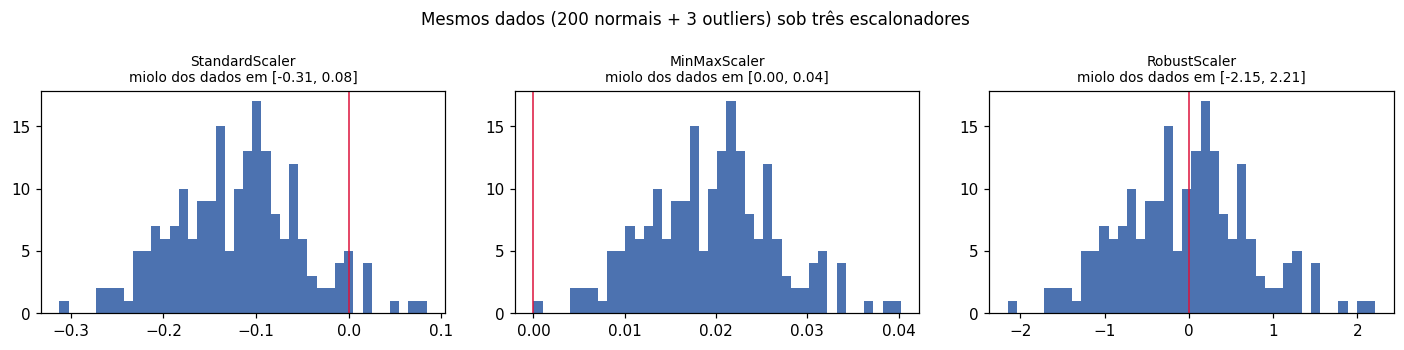

In [14]:
rng = np.random.RandomState(RANDOM_STATE)      # gerador de números aleatórios com semente fixa
x = rng.normal(loc=50, scale=5, size=200)      # 200 valores normais: média 50, desvio 5
x = np.append(x, [500, 600, 700])              # 3 outliers grosseiros grudados no fim do vetor
X_out = x.reshape(-1, 1)                       # vira matriz coluna (203, 1): o sklearn exige 2 dimensões

# Dicionário {nome: dados transformados} para conseguir iterar e plotar de uma vez só.
resultados = {
    "StandardScaler": preprocessing.StandardScaler().fit_transform(X_out),
    "MinMaxScaler":   preprocessing.MinMaxScaler().fit_transform(X_out),
    "RobustScaler":   preprocessing.RobustScaler().fit_transform(X_out),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))        # 1 linha, 3 colunas de gráficos
for ax, (nome, valores) in zip(axes, resultados.items()):    # zip casa cada eixo com um resultado
    ax.hist(valores[:200].ravel(), bins=40, color="#4C72B0")  # [:200] = só o miolo, sem os outliers
    ax.set_title(f"{nome}\nmiolo dos dados em "  # mostra no título o intervalo do miolo
                 f"[{valores[:200].min():.2f}, {valores[:200].max():.2f}]", fontsize=9)
    ax.axvline(0, color="crimson", lw=1)                 # linha vertical marcando o zero
fig.suptitle("Mesmos dados (200 normais + 3 outliers) sob três escalonadores", fontsize=11)  # título geral da figura
fig.tight_layout()                                       # ajusta espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

Repare no eixo x de cada gráfico. Com `MinMaxScaler`, os 200 pontos "normais" ficam
espremidos perto de 0, porque foram os outliers que definiram o máximo. Com
`RobustScaler`, o miolo continua espalhado e legível — só os outliers vão para longe.

In [15]:
robust = preprocessing.RobustScaler().fit(X_out)  # aprende a mediana e o IQR de cada coluna
print("centro (mediana):", robust.center_)   # o que é subtraído (equivalente ao mean_)
print("escala (IQR)    :", robust.scale_)    # o que divide: Q3 - Q1, imune aos extremos

# quantile_range troca os quartis usados no cálculo do IQR (padrão: 25 e 75).
robust_10_90 = preprocessing.RobustScaler(quantile_range=(10.0, 90.0)).fit(X_out)
print("escala com 10–90:", robust_10_90.scale_)   # faixa mais larga -> escala maior

centro (mediana): [50.065]
escala (IQR)    : [6.116]
escala com 10–90: [12.531]


## 1.4. Centralizando matrizes de kernel: `KernelCenterer`

Quando o modelo trabalha com a **matriz de kernel** $K = \phi(X)\phi(X)^T$
(SVM com kernel, `KernelPCA`), não dá para centralizar $X$ diretamente — o espaço
$\phi$ pode ser de dimensão infinita. O `KernelCenterer` centraliza **implicitamente**:

$$\tilde{K} = K - 1_n K - K 1_n + 1_n K 1_n$$

In [16]:
from sklearn.metrics.pairwise import pairwise_kernels    # calcula a matriz de similaridade entre amostras

X_k = np.array([[1., 0., 0.],                 # 3 amostras com 3 features
                [1., 1., 0.],
                [1., 1., 1.]])

# metric="linear" -> K[i,j] = produto escalar entre a amostra i e a amostra j. Resultado: matriz 3x3.
K = pairwise_kernels(X_k, metric="linear")

transformer = preprocessing.KernelCenterer().fit(K)      # aprende as médias de linha/coluna do kernel
K_centrado = transformer.transform(K)                    # aplica a fórmula da célula acima

print("Kernel original:\n", K)                # as similaridades sem centralizar
print("\nKernel centralizado:\n", K_centrado)  # o mesmo kernel, agora centrado
# A soma de cada coluna vira ~0: é a assinatura de dados centralizados no espaço de features.
print("\nsoma de cada coluna (deve ser ~0):", K_centrado.sum(axis=0).round(10))

Kernel original:
 [[1. 1. 1.]
 [1. 2. 2.]
 [1. 2. 3.]]

Kernel centralizado:
 [[ 0.556 -0.111 -0.444]
 [-0.111  0.222 -0.111]
 [-0.444 -0.111  0.556]]

soma de cada coluna (deve ser ~0): [ 0. -0.  0.]


---
# 2. Transformações não lineares

Escalonar (seção 1) é uma transformação **linear**: muda a escala, mas não muda o
*formato* da distribuição. Uma distribuição assimétrica continua assimétrica.

As transformações desta seção são **monotônicas** (preservam a ordem dos valores)
mas **não lineares** — elas remodelam a distribuição:

| Transformador | Para onde leva os dados | Tipo |
|---|---|---|
| `QuantileTransformer(output_distribution="uniform")` | uniforme em [0, 1] | não paramétrico |
| `QuantileTransformer(output_distribution="normal")` | normal (gaussiana) | não paramétrico |
| `PowerTransformer(method="yeo-johnson")` | aproximadamente normal (aceita valores negativos) | paramétrico |
| `PowerTransformer(method="box-cox")` | aproximadamente normal (**exige dados > 0**) | paramétrico |

## 2.1. Mapeando para uma distribuição uniforme: `QuantileTransformer`

A ideia é simples e elegante: substituir cada valor pelo seu **quantil**.
Se um valor é maior que 30% dos dados de treino, ele vira `0.30`.

$$x_{novo} = F(x) \qquad \text{(F = função de distribuição acumulada empírica)}$$

Consequências: os outliers somem (viram simplesmente "o maior", 1.0), mas
**correlações e distâncias entre pontos são distorcidas**.

In [17]:
from sklearn.datasets import load_iris                # dataset clássico, já embutido no sklearn
from sklearn.model_selection import train_test_split  # separa treino e teste

# return_X_y=True devolve (features, alvo) como arrays, em vez do objeto Bunch completo.
X_iris, y_iris = load_iris(return_X_y=True)
Xtr_i, Xte_i, ytr_i, yte_i = train_test_split(X_iris, y_iris, random_state=0)  # 75% treino / 25% teste (proporção padrão)

# n_quantiles = quantos pontos da curva acumulada serão memorizados (não pode passar do nº de amostras).
qt = preprocessing.QuantileTransformer(n_quantiles=100, random_state=0)
Xtr_trans = qt.fit_transform(Xtr_i)     # aprende a distribuição DO TREINO e transforma
Xte_trans = qt.transform(Xte_i)         # aplica a MESMA curva aos dados de teste

quantis = [0, 25, 50, 75, 100]          # mínimo, Q1, mediana, Q3, máximo
print("TREINO - sepal length (cm)")           # rótulo da saída
print("  antes  :", np.percentile(Xtr_i[:, 0], quantis))      # [:, 0] = todas as linhas, coluna 0
print("  depois :", np.percentile(Xtr_trans[:, 0], quantis))  # vira ~[0, 0.25, 0.5, 0.75, 1]
print("\nTESTE - sepal length (cm)  (note: NÃO fica perfeitamente uniforme, e está certo)")  # rótulo da saída
print("  antes  :", np.percentile(Xte_i[:, 0], quantis))  # quantis do teste antes...
print("  depois :", np.percentile(Xte_trans[:, 0], quantis))  # ...e depois da transformação

TREINO - sepal length (cm)
  antes  : [4.3 5.1 5.8 6.5 7.9]
  depois : [0.    0.237 0.51  0.742 1.   ]

TESTE - sepal length (cm)  (note: NÃO fica perfeitamente uniforme, e está certo)
  antes  : [4.4   5.125 5.75  6.175 7.3  ]
  depois : [0.01  0.249 0.48  0.603 0.941]


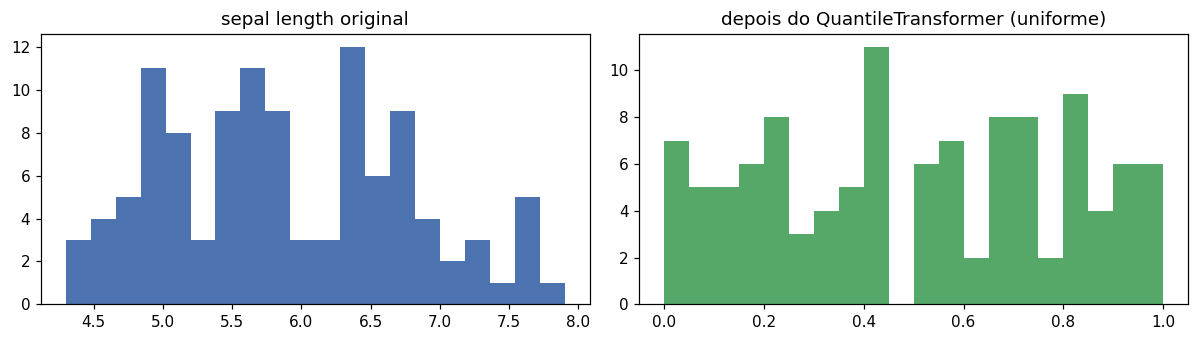

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))               # dois histogramas lado a lado
axes[0].hist(Xtr_i[:, 0], bins=20, color="#4C72B0")             # distribuição original: em forma de sino
axes[0].set_title("sepal length original")    # título do gráfico da esquerda
axes[1].hist(Xtr_trans[:, 0], bins=20, color="#55A868")         # depois: barras de altura parecida
axes[1].set_title("depois do QuantileTransformer (uniforme)")  # título do gráfico da direita
fig.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

> **Cuidado com `n_quantiles`**: ele não pode ser maior que o número de amostras.
> O padrão é 1000; com datasets pequenos o sklearn emite um aviso e reduz o valor.

## 2.2. Mapeando para uma distribuição normal: `PowerTransformer`

Muitas técnicas funcionam melhor com dados próximos da normal. O `PowerTransformer`
busca, **por máxima verossimilhança**, o expoente $\lambda$ que deixa a feature o
mais gaussiana possível.

**Box-Cox** (só para $x > 0$):

$$x^{(\lambda)} = \begin{cases} \dfrac{x^{\lambda} - 1}{\lambda}, & \lambda \neq 0 \\[6pt] \ln(x), & \lambda = 0 \end{cases}$$

**Yeo-Johnson** (aceita zero e negativos — é o padrão):

$$x^{(\lambda)} = \begin{cases}
\dfrac{(x+1)^{\lambda}-1}{\lambda}, & \lambda \neq 0,\; x \geq 0 \\[6pt]
\ln(x+1), & \lambda = 0,\; x \geq 0 \\[6pt]
-\dfrac{(-x+1)^{2-\lambda}-1}{2-\lambda}, & \lambda \neq 2,\; x < 0 \\[6pt]
-\ln(-x+1), & \lambda = 2,\; x < 0
\end{cases}$$

In [19]:
# standardize=False desliga a padronização que o PowerTransformer faz por padrão DEPOIS da potência,
# para vermos o efeito puro da transformação.
pt = preprocessing.PowerTransformer(method="box-cox", standardize=False)

# lognormal gera dados estritamente positivos e assimétricos - o cenário típico de Box-Cox.
X_lognormal = np.random.RandomState(616).lognormal(size=(3, 3))

print("dados log-normais:\n", X_lognormal)    # valores originais, todos positivos
print("\napós Box-Cox:\n", pt.fit_transform(X_lognormal))  # fit e transform em uma chamada só
print("\nlambdas encontrados:", pt.lambdas_)   # um λ por coluna, estimado por máxima verossimilhança

dados log-normais:
 [[1.283 1.181 0.842]
 [0.943 1.61  0.388]
 [1.352 0.217 1.1  ]]

após Box-Cox:
 [[ 0.49   0.179 -0.156]
 [-0.051  0.589 -0.576]
 [ 0.694 -0.849  0.101]]

lambdas encontrados: [4.92  0.863 1.154]


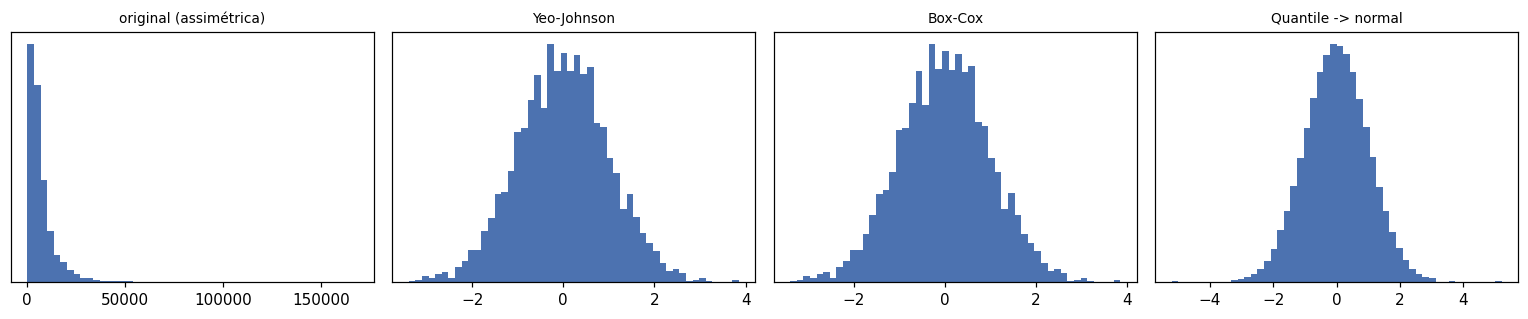

assimetria (skew) original  : 5.999
assimetria após Yeo-Johnson : -0.0
assimetria após Box-Cox     : -0.0
assimetria após Quantile    : 0.005


In [20]:
# Comparação visual em uma distribuição bem assimétrica
rng = np.random.RandomState(RANDOM_STATE)
# mean e sigma aqui são da NORMAL SUBJACENTE: exp(8.5) ~ 4.900 vira o centro da "renda".
renda = rng.lognormal(mean=8.5, sigma=0.9, size=3000).reshape(-1, 1)

yj  = preprocessing.PowerTransformer(method="yeo-johnson").fit_transform(renda)   # padrão do sklearn
bc  = preprocessing.PowerTransformer(method="box-cox").fit_transform(renda)       # exige dados > 0
qtn = preprocessing.QuantileTransformer(output_distribution="normal",             # força o formato normal
                                        n_quantiles=1000, random_state=0).fit_transform(renda)

fig, axes = plt.subplots(1, 4, figsize=(14, 3))  # quatro histogramas lado a lado
# Lista de pares (título, dados) percorrida junto com os eixos.
for ax, (titulo, dados) in zip(axes, [
        ("original (assimétrica)", renda),
        ("Yeo-Johnson", yj),
        ("Box-Cox", bc),
        ("Quantile -> normal", qtn)]):
    ax.hist(dados.ravel(), bins=50, color="#4C72B0")   # ravel() achata (3000,1) em (3000,)
    ax.set_title(titulo, fontsize=9)          # título de cada subgráfico
    ax.set_yticks([])                                  # esconde o eixo y: aqui só o formato interessa
fig.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

from scipy import stats                       # scipy.stats traz medidas como a assimetria
# skew (assimetria): 0 = simétrica; positivo = cauda longa à direita.
print("assimetria (skew) original  :", round(float(stats.skew(renda.ravel())), 3))
print("assimetria após Yeo-Johnson :", round(float(stats.skew(yj.ravel())), 3))  # perto de 0 = simétrica
print("assimetria após Box-Cox     :", round(float(stats.skew(bc.ravel())), 3))  # idem
print("assimetria após Quantile    :", round(float(stats.skew(qtn.ravel())), 3))  # idem

Por padrão `PowerTransformer` já aplica `standardize=True`, ou seja, ele faz a
transformação de potência **e depois** padroniza (média 0, desvio 1).

`QuantileTransformer` também consegue mapear para a normal, e é mais "agressivo":
ele força a distribuição de saída, aconteça o que acontecer. Isso é uma vantagem
com outliers e uma desvantagem quando você quer preservar a estrutura dos dados.

In [21]:
qt_normal = preprocessing.QuantileTransformer(output_distribution="normal",  # saída no formato de uma normal
                                              n_quantiles=100, random_state=0)
X_iris_norm = qt_normal.fit_transform(X_iris)  # aprende os quantis e transforma

# quantiles_ tem shape (n_quantiles, n_features): a "tabela de tradução" aprendida, coluna a coluna.
print("quantis aprendidos (5 primeiros de 100):\n", qt_normal.quantiles_[:5])

print("\nmédia/desvio por feature após transformação:")  # rótulo da saída
print(X_iris_norm.mean(axis=0).round(3), X_iris_norm.std(axis=0).round(3))   # ~0 e ~1, como numa normal padrão

quantis aprendidos (5 primeiros de 100):
 [[4.3   2.    1.    0.1  ]
 [4.4   2.2   1.151 0.1  ]
 [4.401 2.201 1.201 0.1  ]
 [4.552 2.3   1.3   0.152]
 [4.6   2.3   1.3   0.2  ]]

média/desvio por feature após transformação:
[-0.001 -0.001  0.003 -0.031] [1.138 1.138 1.133 1.461]


---
# 3. Normalização (escala **por amostra**)

Atenção à mudança de eixo! Tudo até aqui trabalhou **coluna a coluna**.
A normalização trabalha **linha a linha**: cada amostra é dividida pela sua norma,
virando um vetor de comprimento 1.

$$x_{norm} = \frac{x}{\|x\|}$$

É o coração do *Vector Space Model* em texto: depois de normalizar, o produto
escalar entre duas amostras **é** a similaridade do cosseno, e documentos longos
deixam de ter vantagem sobre documentos curtos só por serem longos.

In [22]:
# Uma lista de listas também serve: o sklearn converte para array internamente.
X_norm_demo = [[ 1., -1.,  2.],
               [ 2.,  0.,  0.],
               [ 0.,  1., -1.]]

# norm="l2": divide cada LINHA pela sua norma euclidiana sqrt(x1² + x2² + x3²).
X_normalized = preprocessing.normalize(X_norm_demo, norm="l2")
print("normalizado (L2):\n", X_normalized)    # cada linha virou um vetor de comprimento 1

# axis=1 = "percorrendo as colunas", ou seja, um valor POR LINHA. Todas devem dar 1.
print("\nnorma de cada linha:", np.linalg.norm(X_normalized, axis=1))

normalizado (L2):
 [[ 0.408 -0.408  0.816]
 [ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]]

norma de cada linha: [1. 1. 1.]


In [23]:
# Versão transformador (para usar dentro de um Pipeline).
# Repare: o fit não aprende nada - é stateless - mas existe por causa da API uniforme.
normalizer = preprocessing.Normalizer().fit(X_norm_demo)

print(normalizer.transform(X_norm_demo))      # mesmo resultado da função normalize
# Como nada foi aprendido, transformar uma amostra nova dá o mesmo resultado de normalizá-la sozinha.
print("\nem uma amostra nova:", normalizer.transform([[-1., 1., 0.]]))

[[ 0.408 -0.408  0.816]
 [ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]]

em uma amostra nova: [[-0.707  0.707  0.   ]]


In [24]:
amostra = [[3., -4., 0.]]                  # vetor de norma L2 = 5 (triângulo 3-4-5)
for norma in ["l1", "l2", "max"]:          # percorre as três normas disponíveis
    # f-string com :>3 alinha o nome da norma à direita em 3 caracteres, só para a saída ficar arrumada.
    print(f"norm={norma:>3}: {preprocessing.normalize(amostra, norm=norma)}")

print("\nl1  -> soma dos valores absolutos = 1")  # lembretes das definições
print("l2  -> comprimento euclidiano = 1")    # sqrt(3² + 4²) = 5, daí 0.6 e -0.8
print("max -> maior valor absoluto = 1")      # divide tudo por 4

norm= l1: [[ 0.429 -0.571  0.   ]]
norm= l2: [[ 0.6 -0.8  0. ]]
norm=max: [[ 0.75 -1.    0.  ]]

l1  -> soma dos valores absolutos = 1
l2  -> comprimento euclidiano = 1
max -> maior valor absoluto = 1


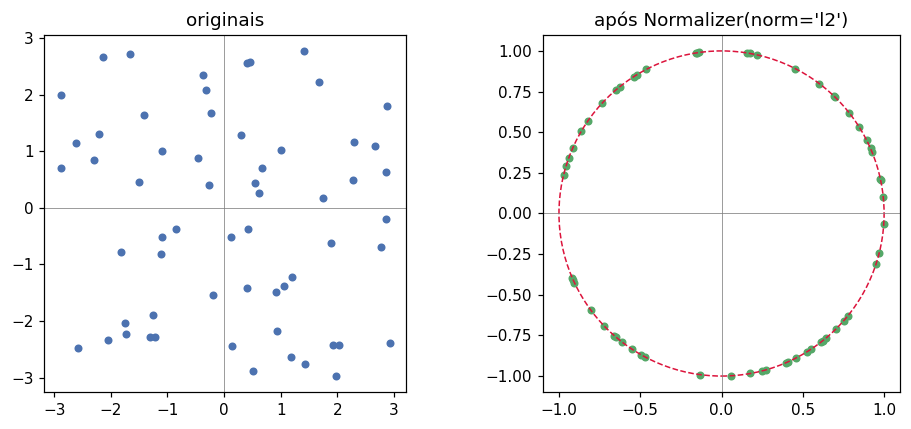

In [25]:
# Visualizando: L2 projeta todos os pontos no círculo de raio 1
rng = np.random.RandomState(0)
pontos = rng.uniform(-3, 3, size=(60, 2))              # 60 pontos espalhados num quadrado
pontos_l2 = preprocessing.normalize(pontos, norm="l2")  # cada ponto vira um vetor de comprimento 1

fig, axes = plt.subplots(1, 2, figsize=(9, 4))  # dois gráficos lado a lado
axes[0].scatter(pontos[:, 0], pontos[:, 1], s=18, color="#4C72B0")      # x = coluna 0, y = coluna 1
axes[0].set_title("originais")                # título do gráfico da esquerda
axes[1].scatter(pontos_l2[:, 0], pontos_l2[:, 1], s=18, color="#55A868")
axes[1].set_title("após Normalizer(norm='l2')")  # título do gráfico da direita

circ = plt.Circle((0, 0), 1, fill=False, color="crimson", ls="--")      # círculo unitário de referência
axes[1].add_patch(circ)                       # insere o círculo no gráfico da direita

for ax in axes:                               # ajustes comuns aos dois gráficos
    ax.set_aspect("equal")                  # mesma escala nos dois eixos, senão o círculo vira elipse
    ax.axhline(0, color="gray", lw=0.5)     # eixo horizontal
    ax.axvline(0, color="gray", lw=0.5)     # eixo vertical
fig.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

> Só a **direção** do vetor sobrevive; a magnitude é descartada. Use normalização
> quando o que importa é o "perfil" da amostra (proporções entre features), não o
> tamanho absoluto dos valores.

Tanto `normalize` quanto `Normalizer` aceitam matrizes esparsas (convertidas para CSR).

---
# 4. Codificando variáveis categóricas

Estimadores do scikit-learn esperam números. Variáveis como
`["masculino", "feminino"]` ou `["Brasil", "Japão", "Chile"]` precisam ser
convertidas — e a escolha da conversão importa muito.

| Encoder | Saída | Quando usar |
|---|---|---|
| `OrdinalEncoder` | 1 coluna, inteiros 0..k-1 | categorias com ordem natural; ou modelos de árvore |
| `OneHotEncoder` | k colunas 0/1 | categorias sem ordem, com modelos lineares / distância |
| `TargetEncoder` | 1 coluna, numérica | alta cardinalidade (CEP, produto, cidade) |

> `LabelEncoder` também existe, mas é destinado ao **alvo `y`**, não às features.

## 4.1. `OrdinalEncoder` — cada categoria vira um inteiro

Simples e compacto. O risco: você cria uma **ordem artificial**. Se
`Brasil=0, Japão=1, Chile=2`, um modelo linear vai "entender" que Chile > Japão > Brasil
e que Japão é a média entre os dois. Para árvores de decisão isso é inofensivo;
para regressão/SVM/KNN é um erro.

In [26]:
enc = preprocessing.OrdinalEncoder()          # sem argumentos: as categorias saem do fit

# Cada COLUNA é uma variável categórica diferente; cada LINHA continua sendo uma amostra.
X_cat = [["masculino", "do Brasil", "usa Safari"],
         ["feminino",  "da Europa", "usa Firefox"]]
enc.fit(X_cat)          # descobre quais categorias existem em cada coluna e as ordena alfabeticamente

print("categorias aprendidas (ordem alfabética):")  # rótulo da saída
# categories_ é uma LISTA de arrays: um array por coluna de entrada.
for i, cats in enumerate(enc.categories_):        # enumerate dá o índice e o valor a cada volta
    print(f"  coluna {i}: {list(cats)}")      # a POSIÇÃO na lista é o código atribuído

# O número atribuído é a POSIÇÃO da categoria dentro do array acima.
print("\ntransformando uma amostra nova:",
      enc.transform([["feminino", "do Brasil", "usa Safari"]]))

categorias aprendidas (ordem alfabética):
  coluna 0: ['feminino', 'masculino']
  coluna 1: ['da Europa', 'do Brasil']
  coluna 2: ['usa Firefox', 'usa Safari']

transformando uma amostra nova: [[0. 1. 1.]]


In [27]:
# Definindo a ordem manualmente - o caso em que OrdinalEncoder brilha.
escolaridade = [["fundamental"], ["mestrado"], ["médio"], ["superior"], ["fundamental"]]

# categories espera UMA LISTA POR COLUNA; aqui só há uma coluna, daí os colchetes externos.
ordem = [["fundamental", "médio", "superior", "mestrado"]]

enc_ord = preprocessing.OrdinalEncoder(categories=ordem)  # usa a ordem informada, não a alfabética
# Agora 0 < 1 < 2 < 3 significa mesmo "menos escolaridade < mais escolaridade".
print(enc_ord.fit_transform(escolaridade).ravel())

[0. 3. 1. 2. 0.]


In [28]:
# Valores faltantes: NaN é propagado por padrão (entra NaN, sai NaN)...
X_nan = [["masculino"], ["feminino"], [np.nan], ["feminino"]]
print("padrão              :", preprocessing.OrdinalEncoder().fit_transform(X_nan).ravel())  # entra NaN, sai NaN

# ...ou você escolhe um código numérico para representá-los.
enc_missing = preprocessing.OrdinalEncoder(encoded_missing_value=-1)
print("encoded_missing=-1  :", enc_missing.fit_transform(X_nan).ravel())  # agora o NaN vira -1

padrão              : [ 1.  0. nan  0.]
encoded_missing=-1  : [ 1.  0. -1.  0.]


In [29]:
# Categoria nunca vista no treino: por padrão o transform levanta erro. Use handle_unknown.
enc_unk = preprocessing.OrdinalEncoder(handle_unknown="use_encoded_value",   # não falhe...
                                       unknown_value=-99)                    # ...use este código
enc_unk.fit([["gato"], ["cachorro"]])            # o treino só conhece gato e cachorro
print(enc_unk.transform([["gato"], ["dragão"]]).ravel())   # "dragão" vira -99

[  1. -99.]


## 4.2. `OneHotEncoder` — uma coluna binária por categoria

Sem ordem inventada: cada categoria vira uma coluna com 0 ou 1
("dummy variables"). O custo é o número de colunas, que cresce com a cardinalidade.

In [30]:
# sparse_output=False devolve um array numpy comum (o padrão seria uma matriz esparsa).
enc = preprocessing.OneHotEncoder(sparse_output=False)

X_cat = [["masculino", "do Brasil", "usa Safari"],  # 2 amostras, 3 colunas categóricas
         ["feminino",  "da Europa", "usa Firefox"]]
enc.fit(X_cat)                                # descobre as categorias de cada coluna

X_novo = [["feminino",  "do Brasil", "usa Safari"],  # duas amostras novas para transformar
          ["masculino", "da Europa", "usa Safari"]]

# get_feature_names_out() devolve os nomes das colunas criadas: x0_feminino, x0_masculino, ...
pd.DataFrame(enc.transform(X_novo), columns=enc.get_feature_names_out())

,x0_feminino,x0_masculino,x1_da Europa,x1_do Brasil,x2_usa Firefox,x2_usa Safari
0,1.0,0.0,0.0,1.0,0.0,1.0
1,0.0,1.0,1.0,0.0,0.0,1.0


> Por padrão a saída é **esparsa** (`scipy.sparse`), o que economiza muita memória
> com alta cardinalidade. Use `sparse_output=False` para ver um array denso, ou
> `.toarray()`.

### Informando as categorias possíveis

Se você sabe que existem categorias que não apareceram na amostra de treino,
declare-as — assim as colunas existem desde o início.

In [31]:
# Uma lista de categorias possíveis para cada coluna, mesmo que não apareçam no treino.
generos   = ["feminino", "masculino"]
locais    = ["da África", "da Ásia", "da Europa", "do Brasil"]  # idem para a coluna 1
browsers  = ["usa Chrome", "usa Firefox", "usa IE", "usa Safari"]  # idem para a coluna 2

enc = preprocessing.OneHotEncoder(categories=[generos, locais, browsers],   # ordem = ordem das colunas
                                  sparse_output=False)
enc.fit(X_cat)                                       # o fit só valida; as categorias já foram fixadas

print("colunas geradas:", len(enc.get_feature_names_out()))   # 2 + 4 + 4 = 10
# "da Ásia" e "usa Chrome" não estavam no treino, mas foram declaradas -> são codificadas normalmente.
print(enc.transform([["feminino", "da Ásia", "usa Chrome"]]))

colunas geradas: 10
[[1. 0. 0. 1. 0. 0. 1. 0. 0. 0.]]


In [32]:
# Sem declarar as categorias, o que fazer com valores desconhecidos no teste?
enc_ign = preprocessing.OneHotEncoder(handle_unknown="ignore",      # não levante erro
                                      sparse_output=False).fit(X_cat)
print("handle_unknown='ignore' -> linha toda de zeros para o valor desconhecido:")  # rótulo da saída
# Só "feminino" era conhecido; os outros dois viram blocos de zeros.
print(enc_ign.transform([["feminino", "da Ásia", "usa Chrome"]]))

handle_unknown='ignore' -> linha toda de zeros para o valor desconhecido:
[[1. 0. 0. 0. 0. 0.]]


### `drop`: evitando colinearidade

Com k colunas binárias, uma delas é sempre redundante (se não é nenhuma das outras,
é essa). Essa redundância — a *dummy variable trap* — atrapalha regressões lineares
sem regularização. `drop="first"` remove a primeira; `drop="if_binary"` só remove
quando a variável tem exatamente 2 categorias.

In [33]:
X_cat3 = [["masculino", "Brasil",  "Safari"],  # 3 amostras
          ["feminino",  "Europa",  "Firefox"],
          ["feminino",  "Ásia",    "Chrome"]]   # 2, 3 e 3 categorias, respectivamente

for drop in [None, "first", "if_binary"]:       # None = não descarta nada (padrão)
    e = preprocessing.OneHotEncoder(drop=drop, sparse_output=False).fit(X_cat3)  # um encoder novo para cada valor de drop
    # str(drop):>10 imprime "None"/"first"/"if_binary" alinhados, para comparar as três saídas.
    print(f"drop={str(drop):>10} -> {len(e.get_feature_names_out()):2d} colunas: "
          f"{list(e.get_feature_names_out())}")

drop=      None ->  8 colunas: ['x0_feminino', 'x0_masculino', 'x1_Brasil', 'x1_Europa', 'x1_Ásia', 'x2_Chrome', 'x2_Firefox', 'x2_Safari']
drop=     first ->  5 colunas: ['x0_masculino', 'x1_Europa', 'x1_Ásia', 'x2_Firefox', 'x2_Safari']
drop= if_binary ->  7 colunas: ['x0_masculino', 'x1_Brasil', 'x1_Europa', 'x1_Ásia', 'x2_Chrome', 'x2_Firefox', 'x2_Safari']


In [34]:
# inverse_transform: voltar dos números para as categorias originais.
e = preprocessing.OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(X_cat3)
X_t = e.transform([["feminino", "Ásia", "Chrome"], ["masculino", "?????", "Safari"]])  # a 2ª amostra traz uma categoria inexistente
print(e.inverse_transform(X_t))    # a categoria desconhecida (só zeros) volta como None

[['feminino' 'Ásia' 'Chrome']
 ['masculino' None 'Safari']]


In [35]:
# Valores faltantes viram uma categoria como outra qualquer (e None é diferente de np.nan!).
X_miss = [["masculino", "Safari"],
          ["feminino",  None],
          [np.nan,      "Firefox"]]

enc = preprocessing.OneHotEncoder(sparse_output=False).fit(X_miss)  # NaN e None entram como categorias comuns
print("categorias:", [list(c) for c in enc.categories_])   # repare no nan/None na lista
print(pd.DataFrame(enc.transform(X_miss), columns=enc.get_feature_names_out()))  # existem colunas para nan e para None

categorias: [['feminino', 'masculino', nan], ['Firefox', 'Safari', None]]
   x0_feminino  x0_masculino  x0_nan  x1_Firefox  x1_Safari  x1_None
0          0.0           1.0     0.0         0.0        1.0      0.0
1          1.0           0.0     0.0         0.0        0.0      1.0
2          0.0           0.0     1.0         1.0        0.0      0.0


## 4.3. Categorias infrequentes

Uma coluna "cidade" pode ter centenas de valores, muitos aparecendo 1 ou 2 vezes.
Criar uma coluna para cada é ruído e desperdício. Os encoders sabem agrupar a
cauda longa em um único balde `infrequent_sklearn`:

- `min_frequency` — contagem (inteiro) ou proporção (float entre 0 e 1) mínima;
- `max_categories` — número máximo de categorias mantidas.

In [36]:
# Constrói uma coluna com frequências bem desiguais: 5, 20, 10 e 3 ocorrências.
# dtype=object mantém as strings; o .T transpõe a linha em coluna (shape (38, 1)).
X_animais = np.array([["cachorro"] * 5 + ["gato"] * 20 +
                      ["coelho"] * 10 + ["cobra"] * 3], dtype=object).T

# min_frequency=6: quem aparecer menos de 6 vezes cai no balde dos infrequentes.
enc = preprocessing.OneHotEncoder(min_frequency=6, sparse_output=False).fit(X_animais)

print("infrequentes:", enc.infrequent_categories_)          # cachorro (5) e cobra (3)
print("colunas     :", list(enc.get_feature_names_out()))   # 3 colunas em vez de 4
print()                                       # só uma linha em branco na saída
print(pd.DataFrame(enc.transform([["cachorro"], ["gato"], ["coelho"], ["cobra"]]),  # cachorro e cobra ativam a MESMA coluna
                   columns=enc.get_feature_names_out(),
                   index=["cachorro", "gato", "coelho", "cobra"]))

infrequentes: [array(['cachorro', 'cobra'], dtype=object)]
colunas     : ['x0_coelho', 'x0_gato', 'x0_infrequent_sklearn']

          x0_coelho  x0_gato  x0_infrequent_sklearn
cachorro        0.0      0.0                    1.0
gato            0.0      1.0                    0.0
coelho          1.0      0.0                    0.0
cobra           0.0      0.0                    1.0


In [37]:
# Com handle_unknown='infrequent_if_exist', categorias NOVAS caem no mesmo balde dos infrequentes.
enc = preprocessing.OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  sparse_output=False, min_frequency=6).fit(X_animais)

print("um 'dragão' no teste ->", enc.transform([["dragão"]]))   # 1 na coluna infrequent_sklearn
print("colunas:", list(enc.get_feature_names_out()))  # a coluna infrequent_sklearn continua lá

um 'dragão' no teste -> [[0. 0. 1.]]
colunas: ['x0_coelho', 'x0_gato', 'x0_infrequent_sklearn']


In [38]:
# max_categories mantém apenas as N categorias mais frequentes; o resto vira infrequente.
enc = preprocessing.OneHotEncoder(max_categories=2, sparse_output=False).fit(X_animais)
print("max_categories=2 ->", list(enc.get_feature_names_out()))  # só gato, a mais frequente, sobrevive

# Os dois critérios podem ser combinados (o mais restritivo prevalece).
enc = preprocessing.OneHotEncoder(min_frequency=4, max_categories=3,
                                  sparse_output=False).fit(X_animais)
print("min_frequency=4, max_categories=3 ->", list(enc.get_feature_names_out()))  # gato e coelho sobrevivem

# O OrdinalEncoder tem exatamente os mesmos parâmetros.
enc_o = preprocessing.OrdinalEncoder(min_frequency=6).fit(X_animais)
print("\nOrdinalEncoder infrequentes:", enc_o.infrequent_categories_)  # mesma lógica, mas com saída em 1 coluna
# cachorro e cobra recebem o MESMO código (o último), porque foram agrupados.
print(enc_o.transform([["cachorro"], ["gato"], ["coelho"], ["cobra"]]).ravel())

max_categories=2 -> ['x0_gato', 'x0_infrequent_sklearn']
min_frequency=4, max_categories=3 -> ['x0_coelho', 'x0_gato', 'x0_infrequent_sklearn']

OrdinalEncoder infrequentes: [array(['cachorro', 'cobra'], dtype=object)]
[2. 1. 0. 2.]


## 4.4. `TargetEncoder` — codificando pela média do alvo

Para **alta cardinalidade** (CEP, id de produto, bairro), one-hot explode o número
de colunas. O `TargetEncoder` substitui cada categoria por uma média do alvo `y`
"encolhida" em direção à média global:

$$S_i = \lambda_i \cdot \underbrace{\bar{y}_i}_{\text{média da categoria}} +
(1 - \lambda_i) \cdot \underbrace{\bar{y}}_{\text{média global}},
\qquad \lambda_i = \frac{n_i}{m + n_i}$$

Categorias raras ($n_i$ pequeno) recebem $\lambda_i$ baixo e ficam próximas da
média global — é isso que evita o overfitting em categorias com 2 ou 3 exemplos.

In [39]:
from sklearn.preprocessing import TargetEncoder  # codifica categorias pela média do alvo

rng = np.random.RandomState(RANDOM_STATE)     # gerador aleatório com semente fixa

# Cidades com frequências muito diferentes: de 200 a apenas 3 amostras.
cidades = np.array(["São Paulo"] * 200 + ["Rio"] * 150 + ["Curitiba"] * 80 +
                   ["Manaus"] * 20 + ["Bagé"] * 3, dtype=object).reshape(-1, 1)

# Alvo contínuo com médias bem diferentes por cidade (é isso que o encoder vai capturar).
medias = {"São Paulo": 8.0, "Rio": 6.0, "Curitiba": 4.0, "Manaus": 9.0, "Bagé": 1.0}
# c[0] pega a string dentro da linha (cada linha é um array de 1 elemento).
y_alvo = np.array([rng.normal(medias[c[0]], 1.5) for c in cidades])

te = TargetEncoder(smooth="auto", random_state=RANDOM_STATE)   # smooth="auto" estima m pelos dados
te.fit(cidades, y_alvo)                                        # diferente dos outros: PRECISA do y

pd.DataFrame({                                # tabela comparando contagem, média bruta e codificação
    "categoria": te.categories_[0],                                      # categorias da coluna 0
    "n": [np.sum(cidades.ravel() == c) for c in te.categories_[0]],      # quantas vezes cada uma aparece
    "média bruta do alvo": [y_alvo[cidades.ravel() == c].mean()          # máscara booleana filtra o y
                            for c in te.categories_[0]],
    "codificação (encolhida)": te.encodings_[0],                         # o valor que o encoder usará
}).assign(**{"média global": te.target_mean_})                           # coluna constante, para comparar

,categoria,n,média bruta do alvo,codificação (encolhida),média global
0,Bagé,3,0.953,1.517,6.651
1,Curitiba,80,4.261,4.276,6.651
2,Manaus,20,8.453,8.402,6.651
3,Rio,150,6.081,6.083,6.651
4,São Paulo,200,7.939,7.936,6.651


Compare as duas últimas colunas: "Bagé", com apenas 3 amostras, teve sua média
(próxima de 1.0) puxada em direção à média global. "São Paulo", com 200 amostras,
praticamente manteve a sua.

> ### ⚠️ `fit_transform` ≠ `fit().transform()`
>
> Esta é a pegadinha mais importante do `TargetEncoder`. Codificar pelo alvo e
> depois treinar nos **mesmos dados** é vazamento puro: a feature já contém a
> resposta. Por isso o `fit_transform` faz **cross-fitting** (validação cruzada
> interna, `cv=5` por padrão): cada dobra é codificada com estatísticas das outras
> dobras.
>
> - **No treino** use `fit_transform(X_train, y_train)`;
> - **no teste** use `transform(X_test)`;
> - dentro de um `Pipeline`, o sklearn já faz a coisa certa automaticamente.

In [40]:
codificado_fit_transform = te.fit_transform(cidades, y_alvo)            # COM cross-fitting
codificado_transform     = te.fit(cidades, y_alvo).transform(cidades)   # SEM cross-fitting

# No primeiro, amostras da mesma cidade recebem valores ligeiramente diferentes (uma por dobra).
print("fit_transform  (5 primeiros):", codificado_fit_transform[:5].ravel())
# No segundo, todas recebem exatamente o mesmo número - e esse número já viu o y delas.
print("fit().transform(5 primeiros):", codificado_transform[:5].ravel())

print("\nsão iguais?", np.allclose(codificado_fit_transform, codificado_transform))  # False: os dois caminhos NÃO são equivalentes
print("-> o fit_transform varia por dobra, é isso que protege contra o vazamento")  # a lição da célula

fit_transform  (5 primeiros): [7.938 7.93  7.894 7.983 7.934]
fit().transform(5 primeiros): [7.936 7.936 7.936 7.936 7.936]

são iguais? False
-> o fit_transform varia por dobra, é isso que protege contra o vazamento


In [41]:
# O parâmetro `smooth` é o "m" da fórmula: quanto maior, mais a categoria é puxada para a média global.
for s in [0.1, 1, 10, 100, "auto"]:
    enc_s = TargetEncoder(smooth=s, random_state=0).fit(cidades, y_alvo)  # um encoder para cada valor de smooth
    # .index(...) acha a posição de "Bagé" na lista de categorias para ler a codificação dela.
    bage = enc_s.encodings_[0][list(enc_s.categories_[0]).index("Bagé")]
    print(f"smooth={str(s):>5} -> codificação de 'Bagé' (n=3): {bage:.3f}")  # quanto maior o smooth, mais perto da média global

# Os dois extremos entre os quais a codificação de Bagé sempre ficará:
print(f"\nmédia global do alvo: {y_alvo.mean():.3f}  |  média bruta de Bagé: "
      f"{y_alvo[cidades.ravel() == 'Bagé'].mean():.3f}")

smooth=  0.1 -> codificação de 'Bagé' (n=3): 1.137
smooth=    1 -> codificação de 'Bagé' (n=3): 2.378
smooth=   10 -> codificação de 'Bagé' (n=3): 5.336
smooth=  100 -> codificação de 'Bagé' (n=3): 6.485
smooth= auto -> codificação de 'Bagé' (n=3): 1.517

média global do alvo: 6.651  |  média bruta de Bagé: 0.953


---
# 5. Discretização (binning)

Discretizar é transformar uma variável **contínua** em **categórica**, agrupando
valores em faixas ("bins"). Também chamado de *quantização* ou *binning*.

**Para que serve?** Dar não linearidade a um modelo linear. Uma regressão linear só
consegue traçar uma reta em `idade`; se você discretiza a idade em faixas e aplica
one-hot, o modelo passa a aprender um coeficiente **independente para cada faixa**
— e ainda continua interpretável.

O preço: perde-se informação dentro de cada faixa, e a fronteira entre bins é
arbitrária.

## 5.1. `KBinsDiscretizer`

Três estratégias de corte:

| `strategy` | Como corta | Quando usar |
|---|---|---|
| `"uniform"` | bins de **largura** igual | distribuição aproximadamente uniforme |
| `"quantile"` | bins com **quantidade** igual de amostras (padrão) | distribuição assimétrica |
| `"kmeans"` | centroides de um k-means 1D | agrupamentos naturais nos dados |

E três codificações (`encode`): `"ordinal"` (um inteiro), `"onehot"` (esparso),
`"onehot-dense"`.

In [42]:
X_bin = np.array([[-3., 5., 15],              # 3 amostras, 3 features
                  [ 0., 6., 14],
                  [ 6., 3., 11]])

est = preprocessing.KBinsDiscretizer(n_bins=[3, 2, 2],      # nº de bins POR COLUNA (pode ser um int único)
                                     encode="ordinal",      # saída: o índice do bin (0, 1, 2...)
                                     strategy="uniform"     # bins de mesma largura
                                     ).fit(X_bin)

print("bordas aprendidas por feature:")       # rótulo da saída
# bin_edges_ é uma lista de arrays: as fronteiras calculadas para cada coluna.
for i, bordas in enumerate(est.bin_edges_):
    print(f"  feature {i}: {bordas}")         # n_bins + 1 fronteiras por coluna

print("\ndiscretizado:\n", est.transform(X_bin))   # cada valor virou o índice do bin em que caiu

bordas aprendidas por feature:
  feature 0: [-3.  0.  3.  6.]
  feature 1: [3.  4.5 6. ]
  feature 2: [11. 13. 15.]

discretizado:
 [[0. 1. 1.]
 [1. 1. 1.]
 [2. 0. 0.]]


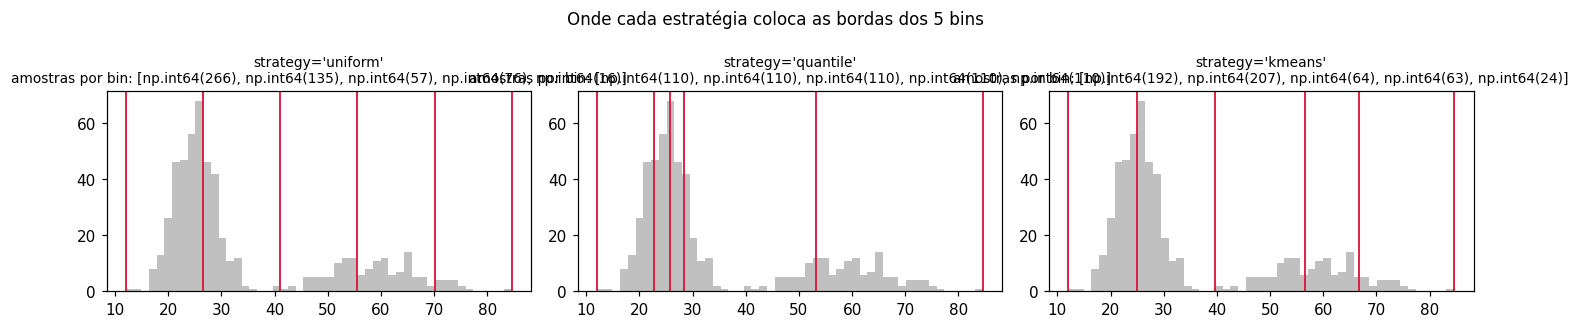

In [43]:
# Comparando as três estratégias em dados com dois grupos bem separados
rng = np.random.RandomState(RANDOM_STATE)
# np.concatenate junta os dois grupos num vetor só; reshape(-1, 1) transforma em matriz coluna.
idade = np.concatenate([rng.normal(25, 4, 400),      # 400 jovens em torno de 25 anos
                        rng.normal(60, 8, 150)]      # 150 mais velhos em torno de 60
                       ).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))  # um gráfico por estratégia
for ax, estrategia in zip(axes, ["uniform", "quantile", "kmeans"]):  # percorre eixo e estratégia em paralelo
    kb = preprocessing.KBinsDiscretizer(n_bins=5, encode="ordinal",  # 5 bins, saída como índice do bin
                                        strategy=estrategia).fit(idade)
    ax.hist(idade.ravel(), bins=50, color="#C0C0C0")          # a distribuição real, ao fundo
    for borda in kb.bin_edges_[0]:                            # [0] = bordas da única coluna
        ax.axvline(borda, color="crimson", lw=1.2)            # desenha cada fronteira de bin

    # bincount conta quantas vezes cada índice de bin apareceu; minlength garante 5 posições.
    contagens = np.bincount(kb.transform(idade).ravel().astype(int), minlength=5)
    ax.set_title(f"strategy='{estrategia}'\namostras por bin: {list(contagens)}", fontsize=9)  # título com a distribuição das amostras

fig.suptitle("Onde cada estratégia coloca as bordas dos 5 bins", fontsize=11)  # título geral da figura
fig.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

Note como `uniform` cria bins quase vazios na região sem dados, enquanto `quantile`
distribui as amostras igualmente (bins estreitos onde há muita gente).

### Discretização ajudando um modelo linear

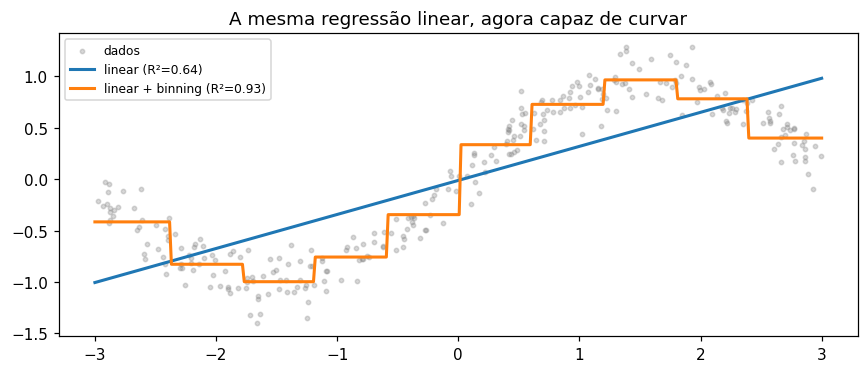

In [44]:
from sklearn.linear_model import LinearRegression  # a regressão linear será nossa cobaia
from sklearn.pipeline import make_pipeline    # encadeia transformador + modelo

rng = np.random.RandomState(0)                # gerador aleatório com semente fixa
x_lin = rng.uniform(-3, 3, 300).reshape(-1, 1)                    # 300 valores de x entre -3 e 3
y_lin = np.sin(x_lin).ravel() + rng.normal(0, 0.15, 300)          # y = seno(x) + ruído: relação NÃO linear
grade = np.linspace(-3, 3, 400).reshape(-1, 1)                    # grade fina, só para desenhar as curvas

linear = LinearRegression().fit(x_lin, y_lin)                     # uma reta tentando acompanhar um seno

binned = make_pipeline(                       # o mesmo modelo, mas com discretização antes
    preprocessing.KBinsDiscretizer(n_bins=10,                     # 10 faixas de x...
                                   encode="onehot-dense",         # ...cada uma vira uma coluna 0/1
                                   strategy="uniform"),
    LinearRegression()                                            # a regressão aprende 1 nível por faixa
).fit(x_lin, y_lin)

plt.figure(figsize=(8, 3.5))                  # cria a figura
plt.scatter(x_lin, y_lin, s=8, alpha=0.3, color="gray", label="dados")   # alpha = transparência
# .score() de um regressor = R² (1.0 seria o ajuste perfeito).
plt.plot(grade, linear.predict(grade), lw=2, label=f"linear (R²={linear.score(x_lin, y_lin):.2f})")
plt.plot(grade, binned.predict(grade), lw=2,  # a curva em degraus do modelo com binning
         label=f"linear + binning (R²={binned.score(x_lin, y_lin):.2f})")
plt.legend(fontsize=8)                        # mostra a legenda
plt.title("A mesma regressão linear, agora capaz de curvar")  # título do gráfico
plt.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

### Bins definidos por você: `FunctionTransformer` + `pd.cut`

Quando as faixas vêm da regra de negócio (faixa etária, faixa de renda do IR),
não há nada a "aprender" — basta aplicar o corte:

In [45]:
bins   = [0, 1, 13, 20, 60, np.inf]                              # 5 faixas -> 6 fronteiras; inf = "para cima"
labels = ["bebê", "criança", "adolescente", "adulto", "idoso"]   # um rótulo por faixa

# FunctionTransformer embrulha qualquer função em um transformador compatível com Pipeline.
transformer = preprocessing.FunctionTransformer(
    pd.cut,                                                      # a função a ser aplicada
    kw_args={"bins": bins, "labels": labels, "retbins": False}    # argumentos nomeados repassados a ela
)

X_idades = np.array([0.2, 2, 15, 25, 97])     # uma idade de cada faixa
print(transformer.fit_transform(X_idades))    # o fit não faz nada; o transform chama pd.cut

['bebê', 'criança', 'adolescente', 'adulto', 'idoso']
Categories (5, object): ['bebê' < 'criança' < 'adolescente' < 'adulto' < 'idoso']


## 5.2. Binarização: `Binarizer`

Caso extremo do binning: **um único limiar**, saída 0 ou 1. Útil quando só importa
"aconteceu ou não" (o cliente comprou alguma vez? a palavra apareceu no texto?),
como nos modelos de Bernoulli (`BernoulliNB`).

In [46]:
X_b = [[ 1., -1.,  2.],                       # a mesma matriz-brinquedo de sempre
       [ 2.,  0.,  0.],
       [ 0.,  1., -1.]]

binarizer = preprocessing.Binarizer().fit(X_b)      # fit não aprende nada (stateless)
# Regra: valor > limiar vira 1; valor <= limiar vira 0. Note que o próprio 0 vira 0.
print("limiar padrão = 0.0:\n", binarizer.transform(X_b))

print("\nlimiar = 1.1:\n", preprocessing.Binarizer(threshold=1.1).transform(X_b))  # agora só o que passa de 1.1 vira 1

# Versão função, sem precisar criar o objeto - útil fora de pipelines.
print("\nfunção binarize:\n", preprocessing.binarize(X_b, threshold=0.5))

limiar padrão = 0.0:
 [[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]

limiar = 1.1:
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 0.]]

função binarize:
 [[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]


> `Binarizer(threshold=t)` é equivalente a um `KBinsDiscretizer` com `k=2` e borda em `t`.

---
# 6. Imputação de valores faltantes

Este é tema do módulo `sklearn.impute`, mas aparece em qualquer pipeline real,
então vale o resumo:

| Classe | Estratégia |
|---|---|
| `SimpleImputer` | média, mediana, mais frequente ou constante |
| `KNNImputer` | média dos k vizinhos mais parecidos |
| `IterativeImputer` | modela cada coluna faltante em função das demais (experimental) |
| `MissingIndicator` | cria coluna booleana marcando onde havia NaN |

Documentação completa: <https://scikit-learn.org/stable/modules/impute.html>

In [47]:
from sklearn.impute import SimpleImputer, MissingIndicator  # a imputação mora em sklearn.impute

# np.nan é o marcador padrão de "faltante" para dados numéricos.
X_faltante = np.array([[ 1.,  2., np.nan],
                       [ 4., np.nan, 6.],
                       [10., 5.,     9.]])

for estrategia in ["mean", "median", "most_frequent"]:  # compara as três estatísticas
    imp = SimpleImputer(strategy=estrategia)     # a estatística é calculada COLUNA A COLUNA, no fit
    # .ravel() achata a matriz para caber em uma linha de saída e facilitar a comparação.
    print(f"{estrategia:>13}:", imp.fit_transform(X_faltante).ravel())

# strategy="constant" + fill_value: você escolhe o valor (comum com dados categóricos).
print("\nconstante (0):", SimpleImputer(strategy="constant",
                                       fill_value=0).fit_transform(X_faltante).ravel())

# MissingIndicator não preenche nada: só devolve True onde havia NaN.
print("\nonde havia NaN (MissingIndicator):\n",
      MissingIndicator().fit_transform(X_faltante))

         mean: [ 1.   2.   7.5  4.   3.5  6.  10.   5.   9. ]
       median: [ 1.   2.   7.5  4.   3.5  6.  10.   5.   9. ]
most_frequent: [ 1.  2.  6.  4.  2.  6. 10.  5.  9.]

constante (0): [ 1.  2.  0.  4.  0.  6. 10.  5.  9.]

onde havia NaN (MissingIndicator):
 [[False  True]
 [ True False]
 [False False]]


> **O fato de um dado faltar pode ser informação.** Se "renda" só falta para quem
> está desempregado, a ausência prediz o alvo. Por isso muitas vezes vale imputar
> **e** guardar o indicador (`SimpleImputer(add_indicator=True)`).

---
# 7. Gerando features polinomiais

Outra forma de dar não linearidade a um modelo linear: em vez de mudar o modelo,
**enriquecer as features**.

## 7.1. `PolynomialFeatures`

Gera todos os produtos de features até um certo grau. De $(x_1, x_2)$ com grau 2:

$$(1,\; x_1,\; x_2,\; x_1^2,\; x_1 x_2,\; x_2^2)$$

In [48]:
from sklearn.preprocessing import PolynomialFeatures  # gera potências e produtos das features

X_poly = np.arange(6).reshape(3, 2)      # 0..5 arrumados em 3 amostras x 2 features
print("original:\n", X_poly)                  # 3 amostras x 2 features

poly = PolynomialFeatures(degree=2)      # até grau 2: inclui quadrados e o produto cruzado
X_expandido = poly.fit_transform(X_poly)      # o fit só conta colunas; o transform faz as contas

# get_feature_names_out aceita os nomes originais e devolve os nomes dos termos gerados.
print("\nnomes das colunas:", list(poly.get_feature_names_out(["x0", "x1"])))
print("expandido:\n", X_expandido)       # a primeira coluna é o termo constante 1 (o intercepto)

original:
 [[0 1]
 [2 3]
 [4 5]]

nomes das colunas: ['1', 'x0', 'x1', 'x0^2', 'x0 x1', 'x1^2']
expandido:
 [[ 1.  0.  1.  0.  0.  1.]
 [ 1.  2.  3.  4.  6.  9.]
 [ 1.  4.  5. 16. 20. 25.]]


In [49]:
X3 = np.arange(9).reshape(3, 3)                        # 3 amostras x 3 features
# interaction_only=True: só produtos de features DIFERENTES (sem x0², x0³...).
poly_i = PolynomialFeatures(degree=3, interaction_only=True)
X3_exp = poly_i.fit_transform(X3)             # gera 1 + 3 + 3 + 1 = 8 colunas

print("nomes:", list(poly_i.get_feature_names_out(["a", "b", "c"])))   # 1, a, b, c, ab, ac, bc, abc
print(X3_exp)                                 # confira: a última coluna é a*b*c

nomes: ['1', 'a', 'b', 'c', 'a b', 'a c', 'b c', 'a b c']
[[  1.   0.   1.   2.   0.   0.   2.   0.]
 [  1.   3.   4.   5.  12.  15.  20.  60.]
 [  1.   6.   7.   8.  42.  48.  56. 336.]]


> **Cuidado com a explosão combinatória.** Com 50 features e grau 3 você gera mais
> de 23 mil colunas. E como $x^3$ tem escala muito diferente de $x$, **padronize
> depois** de expandir. Grau alto também gera oscilações violentas nas bordas
> (fenômeno de Runge).

## 7.2. `SplineTransformer` — a alternativa bem-comportada

Splines são polinômios **por pedaços**, costurados em pontos chamados *nós* (knots).
O `SplineTransformer` gera a base B-spline de cada feature.

Vantagens sobre polinômios de grau alto:

1. flexíveis mesmo com grau baixo (normalmente 3);
2. sem oscilação nas bordas;
3. boas opções de extrapolação (`extrapolation="linear"`, `"constant"`, `"periodic"`);
4. matriz de features em banda, numericamente bem-condicionada.

Limitação: trata cada feature separadamente, **não cria interações**.

In [50]:
from sklearn.preprocessing import SplineTransformer  # base B-spline: polinômios por pedaços

X_s = np.arange(5).reshape(5, 1)                      # 5 amostras de uma única feature: 0, 1, 2, 3, 4
spline = SplineTransformer(degree=2,                  # grau de cada pedaço polinomial
                           n_knots=3)                 # nº de nós -> define quantas colunas saem
# Cada linha tem poucos valores não nulos e eles somam 1: é a "partição da unidade" das B-splines.
print("base B-spline (cada linha soma 1):\n", spline.fit_transform(X_s))

base B-spline (cada linha soma 1):
 [[0.5   0.5   0.    0.   ]
 [0.125 0.75  0.125 0.   ]
 [0.    0.5   0.5   0.   ]
 [0.    0.125 0.75  0.125]
 [0.    0.    0.5   0.5  ]]


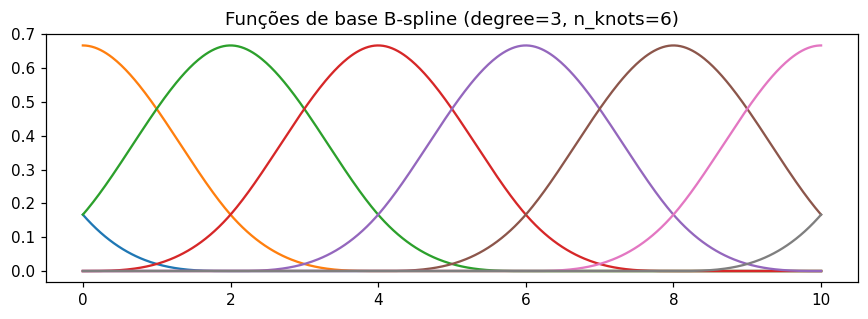

In [51]:
# Como são, visualmente, as funções de base geradas
grade_s = np.linspace(0, 10, 500).reshape(-1, 1)                      # 500 pontos entre 0 e 10
base = SplineTransformer(degree=3, n_knots=6).fit_transform(grade_s)  # matriz (500, n_colunas)

plt.figure(figsize=(8, 3))                    # cria a figura
for j in range(base.shape[1]):              # shape[1] = número de colunas geradas
    plt.plot(grade_s, base[:, j], lw=1.5)   # cada coluna é uma "corcova" ativa em uma região de x
plt.title("Funções de base B-spline (degree=3, n_knots=6)")  # título do gráfico
plt.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

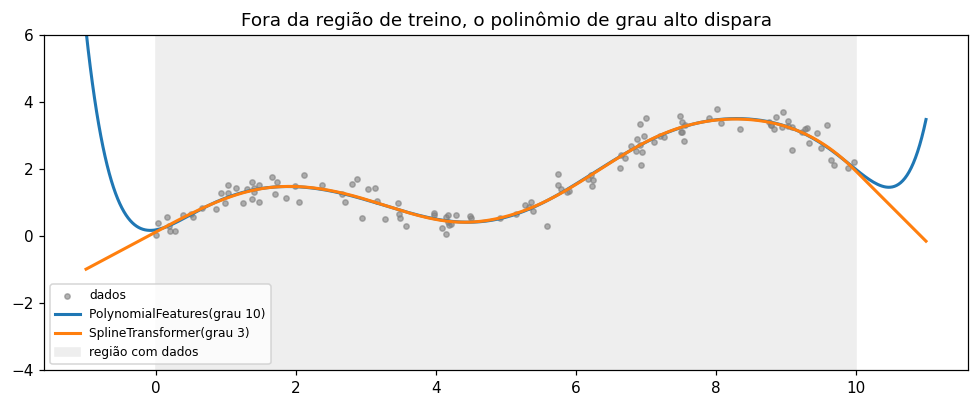

In [52]:
# Polinômio vs. spline ajustando a mesma função não linear
rng = np.random.RandomState(1)
x_f = np.sort(rng.uniform(0, 10, 120)).reshape(-1, 1)             # 120 pontos ordenados entre 0 e 10
y_f = np.sin(x_f).ravel() + 0.3 * x_f.ravel() + rng.normal(0, 0.3, 120)   # onda + tendência + ruído
grade_f = np.linspace(-1, 11, 400).reshape(-1, 1)                 # vai de -1 a 11: extrapola nas duas pontas

mod_poly = make_pipeline(PolynomialFeatures(degree=10),           # grau alto = muita flexibilidade...
                         LinearRegression()).fit(x_f, y_f)
mod_spl  = make_pipeline(SplineTransformer(degree=3, n_knots=8,  # spline de grau baixo com 8 nós
                                           extrapolation="linear"),   # fora do intervalo, segue reto
                         LinearRegression()).fit(x_f, y_f)

plt.figure(figsize=(9, 3.8))                  # cria a figura
plt.scatter(x_f, y_f, s=12, color="gray", alpha=0.6, label="dados")  # os pontos observados
plt.plot(grade_f, mod_poly.predict(grade_f), lw=2, label="PolynomialFeatures(grau 10)")  # previsão do polinômio
plt.plot(grade_f, mod_spl.predict(grade_f), lw=2, label="SplineTransformer(grau 3)")  # previsão da spline
plt.axvspan(0, 10, color="#EEEEEE", zorder=0, label="região com dados")  # faixa cinza de fundo
plt.ylim(-4, 6)                                 # limita o eixo y, senão o polinômio esmaga o gráfico
plt.legend(fontsize=8)                        # mostra a legenda
plt.title("Fora da região de treino, o polinômio de grau alto dispara")  # título do gráfico
plt.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

> `SplineTransformer(degree=0)` é equivalente a
> `KBinsDiscretizer(encode="onehot-dense")` com `n_bins = n_knots - 1`:
> binning é o caso mais simples de spline.

---
# 8. Transformadores customizados

## 8.1. `FunctionTransformer` — sua função virando um transformador

Qualquer função `X -> X'` sem parâmetros a aprender pode entrar num `Pipeline`:

In [53]:
from sklearn.preprocessing import FunctionTransformer  # embrulha uma função em um transformador

# np.log1p calcula log(1 + x): tolera zeros, ao contrário de np.log.
# validate=True faz o sklearn checar e converter a entrada para um array numérico 2D.
transformer = FunctionTransformer(np.log1p, validate=True)
X_log = np.array([[0, 1], [2, 3]])            # há um zero: por isso log1p, e não log

print("log1p:\n", transformer.transform(X_log))    # o fit não faz nada, dá para chamar transform direto

log1p:
 [[0.    0.693]
 [1.099 1.386]]


In [54]:
# Informando a inversa, o objeto passa a saber desfazer a transformação.
log_t = FunctionTransformer(func=np.log1p,       # ida
                            inverse_func=np.expm1,   # volta: exp(x) - 1
                            validate=True)
X_t = log_t.fit_transform(X_log)              # aplica a ida
print("transformado :\n", X_t)                # valores em escala logarítmica
print("de volta     :\n", log_t.inverse_transform(X_t))   # recupera os valores originais

transformado :
 [[0.    0.693]
 [1.099 1.386]]
de volta     :
 [[0. 1.]
 [2. 3.]]


In [55]:
# Com argumentos extras: a função recebe X como 1º argumento e o resto vem de kw_args.
def recorta(X, minimo, maximo):
    return np.clip(X, minimo, maximo)            # np.clip trava os valores no intervalo dado

clipper = FunctionTransformer(recorta, kw_args={"minimo": 0, "maximo": 10})  # os kw_args viram argumentos da função
print(clipper.fit_transform(np.array([[-5., 3., 50.]])))   # -5 vira 0, 3 fica, 50 vira 10

[[ 0.  3. 10.]]


## 8.2. Escrevendo sua própria classe

Quando o transformador precisa **aprender algo no `fit`**, escreva uma classe
herdando de `BaseEstimator` e `TransformerMixin` (esta última dá o `fit_transform`
de graça). Contrato mínimo:

- `fit(self, X, y=None)` aprende e retorna `self`;
- `transform(self, X)` aplica;
- parâmetros do `__init__` guardados com o mesmo nome, sem validação (para que
  `get_params`/`set_params`, e portanto `GridSearchCV`, funcionem);
- atributos aprendidos terminam com `_`.

In [56]:
from sklearn.base import BaseEstimator, TransformerMixin   # BaseEstimator dá get_params/set_params
from sklearn.utils.validation import check_is_fitted       # erro claro se transform vier antes do fit


class WinsorizadorIQR(BaseEstimator, TransformerMixin):  # TransformerMixin dá o fit_transform de graça
    '''Recorta cada coluna no intervalo [Q1 - k*IQR, Q3 + k*IQR] aprendido no fit.'''  # docstring: aparece no help() e no ? do Jupyter

    def __init__(self, k=1.5):                # k = quantos IQRs de folga antes de recortar
        # REGRA DO SKLEARN: o __init__ só guarda o parâmetro, com o mesmo nome, sem validar nem calcular.
        self.k = k

    def fit(self, X, y=None):                      # y é ignorado, mas precisa estar na assinatura
        X = np.asarray(X, dtype=float)             # aceita lista, DataFrame ou array
        q1, q3 = np.percentile(X, [25, 75], axis=0)   # quartis de cada coluna
        iqr = q3 - q1                                  # amplitude interquartil
        self.limite_inferior_ = q1 - self.k * iqr      # atributos aprendidos terminam com "_"
        self.limite_superior_ = q3 + self.k * iqr  # idem para o teto
        self.n_features_in_ = X.shape[1]               # convenção do sklearn: nº de colunas vistas no fit
        return self                                    # SEMPRE retornar self, para permitir encadeamento

    def transform(self, X):                   # aplica o que foi aprendido, sem reaprender nada
        check_is_fitted(self)                      # levanta NotFittedError se o fit não foi chamado
        X = np.asarray(X, dtype=float)        # mesma conversão feita no fit
        return np.clip(X, self.limite_inferior_, self.limite_superior_)  # recorta coluna a coluna (broadcasting)


rng = np.random.RandomState(0)                # gerador aleatório com semente fixa
# np.r_ empilha arrays verticalmente: 200 valores normais + 2 outliers absurdos.
X_w = np.r_[rng.normal(10, 2, (200, 1)), [[200.], [-150.]]]

w = WinsorizadorIQR(k=1.5).fit(X_w)           # aprende os limites
X_wt = w.transform(X_w)                       # aplica o recorte

print("limites aprendidos:", w.limite_inferior_.round(2), w.limite_superior_.round(2))  # os atributos que terminam em _
print("antes  -> min/max:", X_w.min().round(2), "/", X_w.max().round(2))  # -150 e 200
print("depois -> min/max:", X_wt.min().round(2), "/", X_wt.max().round(2))  # agora tudo dentro dos limites

# Como respeitamos o contrato, a classe se encaixa em um Pipeline como qualquer transformador nativo.
print("\nfunciona em Pipeline:", make_pipeline(WinsorizadorIQR(),
                                              preprocessing.StandardScaler()).fit(X_w))

limites aprendidos: [3.9] [16.28]
antes  -> min/max: -150.0 / 200.0
depois -> min/max: 3.9 / 16.28

funciona em Pipeline: Pipeline(steps=[('winsorizadoriqr', WinsorizadorIQR()),
                ('standardscaler', StandardScaler())])


---
# 9. Juntando tudo: `ColumnTransformer` + `Pipeline`

Na prática, colunas diferentes precisam de tratamentos diferentes. O
`ColumnTransformer` aplica cada transformador ao seu subconjunto de colunas e
concatena os resultados — tudo dentro de um único objeto que respeita
`fit`/`transform` e, portanto, não vaza dados.

In [57]:
rng = np.random.RandomState(RANDOM_STATE)     # gerador aleatório com semente fixa
n = 800                                            # número de clientes fictícios

df = pd.DataFrame({                           # monta a tabela de clientes, coluna a coluna
    "idade":      rng.randint(18, 80, n).astype(float),        # inteiros entre 18 e 79
    "renda":      rng.lognormal(8.2, 0.7, n),                  # assimétrica, de propósito
    "n_compras":  rng.poisson(3, n).astype(float),             # contagem, média 3
    "cidade":     rng.choice(["São Paulo", "Rio", "Curitiba", "Manaus", "Bagé"],
                             n, p=[.45, .25, .15, .1, .05]),   # p = probabilidade de cada categoria
    "plano":      rng.choice(["free", "plus", "premium"], n, p=[.6, .3, .1]),
    "escolaridade": rng.choice(["fundamental", "médio", "superior", "mestrado"], n),
})

# Injeta valores faltantes de propósito: rng.choice sorteia quais linhas serão apagadas.
df.loc[rng.choice(n, 60, replace=False), "renda"] = np.nan     # replace=False: sem repetir linhas
df.loc[rng.choice(n, 30, replace=False), "cidade"] = np.nan  # idem para a cidade, em 30 linhas

# Alvo: churn (1 = cancelou). Construído como uma regressão logística "de mentira",
# para sabermos exatamente quais variáveis carregam sinal.
efeito_cidade = {"São Paulo": -0.4, "Rio": 0.3, "Curitiba": -0.8, "Manaus": 0.9, "Bagé": 1.4}
renda_preenchida = df["renda"].fillna(df["renda"].median())    # só para montar o alvo, sem NaN

logit = (-0.3                                 # -0.3 é o intercepto: o risco de base
         + 1.8 * (df["plano"] == "free")           # comparação booleana vira 1/0 na conta
         - 0.9 * (df["plano"] == "premium")
         - 0.045 * (df["idade"] - 45)              # mais velho -> menos churn
         - 0.9 * (renda_preenchida > 4000)
         - 0.25 * df["n_compras"]
         + df["cidade"].map(efeito_cidade).fillna(0.0))   # .map traduz categoria -> número

# 1/(1+exp(-logit)) converte o logit em probabilidade; binomial sorteia o 0/1 final.
y = rng.binomial(1, 1 / (1 + np.exp(-logit)))

print(f"taxa de churn: {y.mean():.2%}   |   valores faltantes por coluna:")  # :.2% formata o número como porcentagem
print(df.isna().sum().to_dict())              # isna() marca os NaN; sum() conta por coluna
df.head()                                     # a última expressão da célula é exibida pelo Jupyter

taxa de churn: 36.00%   |   valores faltantes por coluna:
{'idade': 0, 'renda': 60, 'n_compras': 0, 'cidade': 30, 'plano': 0, 'escolaridade': 0}


,idade,renda,n_compras,cidade,plano,escolaridade
0,56.0,7994.261,5.0,São Paulo,plus,fundamental
1,69.0,16321.583,5.0,Rio,premium,fundamental
2,46.0,2864.611,5.0,São Paulo,plus,médio
3,32.0,4335.188,1.0,São Paulo,free,médio
4,60.0,NaN,7.0,São Paulo,free,mestrado


In [58]:
from sklearn.compose import ColumnTransformer      # aplica transformadores diferentes por grupo de colunas
from sklearn.pipeline import Pipeline              # versão nomeada do make_pipeline
from sklearn.impute import SimpleImputer      # para preencher os NaN que criamos acima
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder,  # os parênteses permitem importar em várias linhas
                                   PowerTransformer, KBinsDiscretizer)

# Agrupamos as colunas por TRATAMENTO desejado, não por tipo de dado.
num_padrao   = ["n_compras"]        # numérica bem-comportada -> padronizar
num_assimetr = ["renda"]            # numérica torta -> transformar e padronizar
num_faixas   = ["idade"]            # numérica que queremos em faixas
cat_nominal  = ["cidade", "plano"]  # categóricas sem ordem -> one-hot
cat_ordinal  = ["escolaridade"]     # categórica COM ordem -> ordinal

ordem_escolaridade = [["fundamental", "médio", "superior", "mestrado"]]  # a ordem que dá sentido aos inteiros

pre = ColumnTransformer(                      # o pré-processador completo, coluna por coluna
    transformers=[
        # Cada tupla é (nome, transformador, colunas). O nome aparece nos parâmetros e nos logs.
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),   # 1º imputa
                          ("sc",  StandardScaler())]),                 # 2º padroniza
         num_padrao),

        ("assimetrica", Pipeline([("imp", SimpleImputer(strategy="median")),
                                  ("pw",  PowerTransformer())]),       # Yeo-Johnson + padronização
         num_assimetr),

        ("faixas", KBinsDiscretizer(n_bins=5, encode="onehot-dense",
                                    strategy="quantile"),              # 5 faixas com o mesmo nº de pessoas
         num_faixas),

        ("nominal", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),   # NaN -> moda
                              ("oh",  OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                    min_frequency=0.03,           # <3% vira infrequente
                                                    sparse_output=False))]),
         cat_nominal),

        ("ordinal", OrdinalEncoder(categories=ordem_escolaridade), cat_ordinal),
    ],
    remainder="drop",                      # colunas não listadas são descartadas ("passthrough" as manteria)
    verbose_feature_names_out=True,        # prefixa os nomes de saída com o nome do bloco
)

# O Pipeline final: pré-processamento + classificador, em um único objeto treinável.
modelo = Pipeline([("pre", pre),
                   ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
modelo                                     # exibe o diagrama interativo do pipeline

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['n_compras']),
                                                 ('assimetrica',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('pw',
                                                                   PowerTransformer())]),
                                                  ['renda']),
                                                 ('faixas',
                                                  KBinsDiscretizer(encode='onehot-dense'),
                                                  ['idade']),
                                                 ('nominal',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.03,
                                                                                 sparse_output=False))]),
                                                  ['cidade', 'plano']),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['fundamental',
                                                                              'médio',
                                                                              'superior',
                                                                              'mestrado']]),
                                                  ['escolaridade'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [59]:
from sklearn.model_selection import cross_val_score  # avalia o pipeline inteiro por validação cruzada

# stratify=y mantém a proporção de churn igual em treino e teste.
Xtr, Xte, ytr, yte = train_test_split(df, y, test_size=0.25,
                                      stratify=y, random_state=RANDOM_STATE)

modelo.fit(Xtr, ytr)     # um único fit treina imputadores, encoders, scalers E o classificador

print(f"acurácia no teste  : {modelo.score(Xte, yte):.3f}"  # acurácia = fração de acertos
      f"   (chutar a classe majoritária daria {max(yte.mean(), 1 - yte.mean()):.3f})")
# cross_val_score refaz todo o pré-processamento dentro de cada uma das 5 dobras: zero vazamento.
print(f"AUC em CV (treino) : "
      f"{cross_val_score(modelo, Xtr, ytr, cv=5, scoring='roc_auc').mean():.3f}")

# named_steps dá acesso a qualquer etapa pelo nome que demos a ela.
nomes = modelo.named_steps["pre"].get_feature_names_out()
print(f"\n{len(nomes)} features geradas a partir de {df.shape[1]} colunas originais:")  # df.shape[1] = número de colunas do DataFrame
print(list(nomes))                            # os nomes finais, com o prefixo de cada bloco

acurácia no teste  : 0.720   (chutar a classe majoritária daria 0.640)


AUC em CV (treino) : 0.791

16 features geradas a partir de 6 colunas originais:
['num__n_compras', 'assimetrica__renda', 'faixas__idade_0.0', 'faixas__idade_1.0', 'faixas__idade_2.0', 'faixas__idade_3.0', 'faixas__idade_4.0', 'nominal__cidade_Bagé', 'nominal__cidade_Curitiba', 'nominal__cidade_Manaus', 'nominal__cidade_Rio', 'nominal__cidade_São Paulo', 'nominal__plano_free', 'nominal__plano_plus', 'nominal__plano_premium', 'ordinal__escolaridade']


In [60]:
# Espiando a matriz que o classificador realmente recebe (5 primeiras linhas do treino).
X_transformado = modelo.named_steps["pre"].transform(Xtr.head())

# .T transpõe: features viram linhas, o que cabe melhor na tela quando há muitas colunas.
pd.DataFrame(X_transformado, columns=nomes, index=Xtr.head().index).T

,339,556,3,342,742
num__n_compras,0.507,-0.050,-1.164,-0.05,-0.05
assimetrica__renda,0.351,0.055,0.176,-1.43,1.40
faixas__idade_0.0,0.000,0.000,0.000,0.00,0.00
faixas__idade_1.0,0.000,0.000,1.000,0.00,0.00
faixas__idade_2.0,0.000,0.000,0.000,1.00,1.00
faixas__idade_3.0,1.000,1.000,0.000,0.00,0.00
faixas__idade_4.0,0.000,0.000,0.000,0.00,0.00
nominal__cidade_Bagé,0.000,0.000,0.000,0.00,0.00
nominal__cidade_Curitiba,1.000,0.000,0.000,0.00,1.00
nominal__cidade_Manaus,0.000,0.000,0.000,0.00,0.00


### Saída em DataFrame: `set_output`

Desde a versão 1.2, qualquer transformador pode devolver um `DataFrame` com nomes
de coluna — ótimo para depurar e para explicar o modelo em aula.

In [61]:
pre_df = pre.set_output(transform="pandas")   # muda o formato de saída de array numpy para DataFrame
pre_df.fit(Xtr, ytr)                          # precisa refazer o fit após clonar/alterar a configuração
pre_df.transform(Xte.head(3))                 # agora o resultado sai com nomes de coluna

,num__n_compras,assimetrica__renda,faixas__idade_0.0,faixas__idade_1.0,faixas__idade_2.0,faixas__idade_3.0,faixas__idade_4.0,nominal__cidade_Bagé,nominal__cidade_Curitiba,nominal__cidade_Manaus,nominal__cidade_Rio,nominal__cidade_São Paulo,nominal__plano_free,nominal__plano_plus,nominal__plano_premium,ordinal__escolaridade
684,-1.164,1.224,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
720,-0.607,-0.150,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
761,0.507,0.346,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,3.0


> Um `Pipeline` completo é serializável (`joblib.dump`) e vira o artefato de
> produção: o mesmo objeto que treinou é o que transforma os dados na inferência,
> eliminando o clássico "esqueci de aplicar o scaler na API".

---
# 10. Colinha final

## Qual escalonador usar?

```
Tem outliers pesados?  ── sim ──> RobustScaler  (ou QuantileTransformer)
        │
        não
        │
Dados esparsos?  ── sim ──> MaxAbsScaler  /  StandardScaler(with_mean=False)
        │
        não
        │
Precisa de intervalo fixo [0,1]?  ── sim ──> MinMaxScaler
        │
        não
        │
        └──> StandardScaler   (a escolha padrão)
```

## Qual encoder usar?

```
A categoria tem ordem natural (escolaridade, faixa)? ──> OrdinalEncoder(categories=[...])
Modelo baseado em árvores?                           ──> OrdinalEncoder (simples e barato)
Poucas categorias, modelo linear/distância?          ──> OneHotEncoder
Muitas categorias (CEP, produto, cidade)?            ──> TargetEncoder
                                                      ou OneHotEncoder(min_frequency=...)
```

## Precisa de escalonamento?

| Modelo | Precisa? |
|---|---|
| Regressão linear/logística **com** regularização (L1/L2) | sim |
| SVM, KNN, k-means, PCA | sim |
| Redes neurais (MLP) | sim |
| Árvore de decisão, Random Forest, Gradient Boosting, XGBoost | não |
| Naive Bayes | não |

## Erros clássicos

1. `fit_transform` no dataset inteiro antes do `train_test_split` → **leakage**;
2. `fit` separado no treino e no teste → escalas diferentes, modelo inútil;
3. one-hot em variável de altíssima cardinalidade → milhares de colunas ruidosas;
4. `TargetEncoder` com `fit().transform()` no treino em vez de `fit_transform` → leakage;
5. `PolynomialFeatures` sem padronizar depois → termos em escalas incompatíveis;
6. `MinMaxScaler` em dados com outliers → todo o resto espremido perto de zero;
7. imputar a média **antes** de separar treino/teste → leakage silencioso.

---
# 11. Exercícios

Antes dos enunciados, um assunto que costuma travar o aluno mais do que o próprio
scikit-learn: **de onde saem os dados**.

## 11.0. As quatro fontes de dados que usaremos

| Fonte | Como se obtém | Precisa de internet? | Quando usar |
|---|---|---|---|
| **Datasets embutidos** | `from sklearn.datasets import load_iris` | não | testes rápidos, aula, sala sem rede |
| **Geradores sintéticos** | `make_classification`, `np.random` | não | quando você quer *controlar* o problema (e saber a resposta certa) |
| **Repositórios públicos** | `fetch_openml`, `ucimlrepo` | sim (baixa e guarda em cache) | dados reais, bagunçados, com NaN e categóricas |
| **Arquivos locais** | `pd.read_csv("caminho/arquivo.csv")` | não | dados da empresa, do professor, do Kaggle |

### Regra prática

- **Dado embutido ou gerado** → para estudar o *comportamento* de um transformador.
  Você sabe qual é a resposta certa, então consegue verificar se entendeu.
- **Dado real** → para sentir os problemas de verdade: NaN, categorias raras,
  outliers, colunas em escalas malucas.

Os quatro caminhos estão demonstrados na célula abaixo — rode-a antes de começar.

In [62]:
# ----------------------------------------------------------------------------------
# FONTE 1: datasets embutidos no scikit-learn (vêm instalados junto com a biblioteca)
# ----------------------------------------------------------------------------------
from sklearn.datasets import load_breast_cancer        # load_* = já está no seu disco, não baixa nada

# as_frame=True devolve um objeto com .frame (DataFrame), .data (X) e .target (y) em pandas.
cancer = load_breast_cancer(as_frame=True)
print("FONTE 1 - load_breast_cancer:", cancer.data.shape, "| alvo:", cancer.target.name)  # shape = (linhas, colunas)
print("   5 primeiras colunas:", list(cancer.data.columns[:5]))  # os nomes das features
print("   DESCR tem a documentação completa:", len(cancer.DESCR), "caracteres")  # DESCR = texto explicando cada coluna

# Outros embutidos úteis: load_iris, load_wine, load_digits, load_diabetes (regressão),
# load_linnerud. Todos aceitam as_frame=True e return_X_y=True.

# ----------------------------------------------------------------------------------
# FONTE 2: geradores sintéticos (você escolhe o tamanho, o ruído e a dificuldade)
# ----------------------------------------------------------------------------------
from sklearn.datasets import make_classification, make_regression

X_syn, y_syn = make_classification(           # devolve X (features) e y (alvo) já separados
    n_samples=500,          # linhas
    n_features=8,           # colunas no total
    n_informative=3,        # quantas realmente ajudam a prever
    n_redundant=2,          # combinações lineares das informativas
    weights=[0.8, 0.2],     # 80% classe 0, 20% classe 1: dataset desbalanceado
    random_state=42,        # semente: o mesmo dataset para a turma inteira
)
print("\nFONTE 2 - make_classification:", X_syn.shape, "| proporção da classe 1:", y_syn.mean())  # a média de um alvo 0/1 é a proporção de 1s

# ----------------------------------------------------------------------------------
# FONTE 3: repositórios públicos (baixam pela internet e guardam em cache no disco)
# ----------------------------------------------------------------------------------
from sklearn.datasets import fetch_openml              # fetch_* = baixa na primeira vez

try:                                          # se a fonte falhar, seguimos sem quebrar a célula
    # version=1 fixa a versão do dataset: sem isso o OpenML pode devolver outra revisão amanhã.
    titanic = fetch_openml("titanic", version=1, as_frame=True)
    print("\nFONTE 3 - fetch_openml('titanic'):", titanic.frame.shape)  # .frame traz features e alvo num DataFrame só
    print("   colunas:", list(titanic.frame.columns))  # dado cru: tem texto, NaN e colunas inúteis
except Exception as erro:                              # sem rede? o notebook continua funcionando
    titanic = None                            # marca que esta fonte não está disponível
    print("\nFONTE 3 - indisponível agora:", type(erro).__name__)  # informa o tipo do erro e segue em frente

# O cache fica em ~/scikit_learn_data: da segunda vez em diante, carrega do disco.
# Alternativa para dados da UCI:  from ucimlrepo import fetch_ucirepo
#                                 heart = fetch_ucirepo(id=45)   # como na AULA 2

# ----------------------------------------------------------------------------------
# FONTE 4: arquivos locais (o caso mais comum no trabalho de verdade)
# ----------------------------------------------------------------------------------
from pathlib import Path                               # lida com caminhos sem quebrar no Windows

# Path("..") sobe um diretório a partir da pasta deste notebook (2tsCPS-4/REVISAO).
caminho_csv = Path("..") / "AULA1" / "titanic_tratado.csv"

if caminho_csv.exists():                               # sempre teste antes de ler
    df_local = pd.read_csv(caminho_csv)                # sep="," e decimal="." são o padrão
    print("\nFONTE 4 - CSV local:", df_local.shape, "| colunas:", list(df_local.columns)[:6])  # confira o shape logo após ler um arquivo
else:                                         # arquivo ausente: avisa em vez de estourar um erro
    print("\nFONTE 4 - arquivo não encontrado em", caminho_csv)  # mensagem clara em vez de traceback

# Para CSV brasileiro (separador ; e vírgula decimal), use:
#   pd.read_csv(caminho, sep=";", decimal=",", encoding="utf-8")

FONTE 1 - load_breast_cancer: (569, 30) | alvo: target
   5 primeiras colunas: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
   DESCR tem a documentação completa: 4794 caracteres

FONTE 2 - make_classification: (500, 8) | proporção da classe 1: 0.2

FONTE 3 - fetch_openml('titanic'): (1309, 14)
   colunas: ['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']

FONTE 4 - CSV local: (773, 16) | colunas: ['survived', 'pclass', 'sex_0', 'age', 'sibsp', 'parch']


---
## Exercício 1 — Escolhendo o escalonador certo na presença de outliers

**Objetivo:** provar, com números e gráficos, por que `RobustScaler` existe.

### Passo 1 — Colete os dados

Aqui os dados são **gerados**, não baixados: queremos controlar exatamente quantos
outliers existem e onde eles estão. Use a célula de coleta abaixo (já pronta).

O cenário simula o **salário mensal** de 500 funcionários de uma empresa:
a maioria ganha em torno de R$ 5.000, mas 5 diretores ganham R$ 200.000.

### Passo 2 — Explore antes de transformar

1. Calcule `média`, `mediana`, `desvio-padrão` e `IQR` da coluna `salario`.
2. Responda: por que a média está tão acima da mediana?
3. Faça um `boxplot` (`plt.boxplot`) e identifique visualmente os outliers.

### Passo 3 — Compare os três escalonadores

Aplique `StandardScaler`, `MinMaxScaler` e `RobustScaler`. Para cada um:

1. transforme a coluna `salario`;
2. calcule em que intervalo caem os **495 salários normais** (ignore os 5 diretores);
3. monte um `DataFrame` comparativo com as colunas
   `escalonador | mínimo dos 495 | máximo dos 495 | amplitude ocupada`;
4. plote os três histogramas lado a lado (só dos 495 valores normais).

### Passo 4 — Teste o efeito em um modelo

Use `y = (salario > 8000).astype(int)` como alvo artificial e compare a acurácia de
um `KNeighborsClassifier(n_neighbors=5)` com cada escalonador, sempre dentro de um
`make_pipeline` e avaliado com `cross_val_score(..., cv=5)`.

### O que entregar

Uma frase respondendo: **qual escalonador você usaria neste dataset e por quê?**
Cite o número da amplitude ocupada pelos 495 salários normais como argumento.

> **Dica:** `np.percentile(x, [25, 75])` dá Q1 e Q3; o IQR é a diferença entre eles.

In [63]:
# ============================ COLETA DE DADOS - EXERCÍCIO 1 ============================
# Fonte: gerador sintético (não precisa de internet).
rng_ex1 = np.random.RandomState(7)                     # semente própria do exercício

salarios = rng_ex1.normal(loc=5000, scale=1200, size=495)   # 495 salários "normais"
salarios = np.clip(salarios, 1500, None)                    # ninguém ganha menos que R$ 1.500
diretores = np.array([180_000, 195_000, 200_000, 240_000, 310_000])   # os 5 outliers

# np.concatenate junta os dois vetores; reshape(-1, 1) deixa no formato (500, 1) que o sklearn exige.
X_ex1 = np.concatenate([salarios, diretores]).reshape(-1, 1)

# Um DataFrame facilita explorar com .describe(), .plot(), etc.
df_ex1 = pd.DataFrame(X_ex1, columns=["salario"])
print("shape:", df_ex1.shape)                 # 500 linhas, 1 coluna
print(df_ex1["salario"].describe().round(2))           # describe() já mostra média, desvio e quartis

# A PARTIR DAQUI É COM VOCÊ: passos 2, 3 e 4 do enunciado.

shape: (500, 1)
count       500.00
mean       7120.81
std       22447.20
min        1500.00
25%        4204.64
50%        4922.24
75%        5732.16
max      310000.00
Name: salario, dtype: float64


---
## Exercício 2 — Medindo o tamanho do vazamento (data leakage)

**Objetivo:** produzir, com as suas próprias mãos, uma métrica mentirosa — e depois
a métrica honesta.

### Passo 1 — Colete os dados

`load_breast_cancer` vem **embutido** no scikit-learn: não precisa de internet nem
de download. São 569 exames de tumores, 30 features numéricas contínuas (raio,
textura, perímetro...) e um alvo binário (0 = maligno, 1 = benigno).

Leia a descrição do dataset com `print(dados.DESCR[:1500])` antes de modelar —
esse é um hábito que separa quem analisa de quem só roda código.

### Passo 2 — O jeito errado (vazamento)

```python
X_vazado = StandardScaler().fit_transform(X)     # fit no dataset INTEIRO
scores_errados = cross_val_score(SVC(), X_vazado, y, cv=5)
```

### Passo 3 — O jeito certo (pipeline)

```python
modelo = make_pipeline(StandardScaler(), SVC())
scores_certos = cross_val_score(modelo, X, y, cv=5)
```

### Passo 4 — Compare e explique

1. Imprima a média e o desvio-padrão dos dois vetores de scores.
2. A diferença foi grande? Com `StandardScaler` ela costuma ser pequena.
   **Agora repita tudo trocando `StandardScaler` por
   `QuantileTransformer(n_quantiles=100)`** e veja a diferença crescer.
3. Explique, em duas frases, *qual informação* do conjunto de validação escapou
   para dentro do treino em cada caso.

### Passo 5 — O caso extremo

Para ver o vazamento em tamanho industrial, rode o experimento abaixo e explique
o resultado absurdo:

```python
rng = np.random.RandomState(0)
X_ruido = rng.normal(size=(100, 5000))      # 5000 colunas de RUÍDO PURO
y_ruido = rng.randint(0, 2, 100)            # alvo sorteado, sem nenhuma relação com X

# Seleção de features feita ANTES da validação cruzada = vazamento clássico
from sklearn.feature_selection import SelectKBest, f_classif
X_sel = SelectKBest(f_classif, k=20).fit_transform(X_ruido, y_ruido)
print("acurácia com vazamento:", cross_val_score(LogisticRegression(), X_sel, y_ruido, cv=5).mean())

# O jeito certo: a seleção entra no pipeline
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())
print("acurácia honesta     :", cross_val_score(pipe, X_ruido, y_ruido, cv=5).mean())
```

### O que entregar

Uma tabela com as 4 acurácias (errada/certa em cada experimento) e um parágrafo
explicando por que a acurácia honesta do último caso fica perto de 0.50 — e por que
**tinha** que ficar.

In [64]:
# ============================ COLETA DE DADOS - EXERCÍCIO 2 ============================
# Fonte: dataset embutido no scikit-learn (offline).
from sklearn.datasets import load_breast_cancer

dados_ex2 = load_breast_cancer(as_frame=True)          # as_frame=True -> X vem como DataFrame
X_ex2 = dados_ex2.data                                 # 569 linhas x 30 colunas numéricas
y_ex2 = dados_ex2.target                               # 0 = maligno, 1 = benigno

print("X:", X_ex2.shape, "| y:", y_ex2.shape)  # 569 exames, 30 features numéricas
print("proporção de cada classe:", np.bincount(y_ex2).tolist())   # [maligno, benigno]
print("\nprimeiras colunas:", list(X_ex2.columns[:6]))  # todas contínuas, nenhuma categórica
# Escalas MUITO diferentes entre colunas: é por isso que este dataset é bom para o exercício.
print("\nescala de cada coluna (5 primeiras):")
print(X_ex2.iloc[:, :5].agg(["min", "max"]).round(2))  # iloc[:, :5] pega as 5 primeiras colunas; agg aplica min e max

# Leia a documentação do dataset (descomente):
# print(dados_ex2.DESCR[:1500])

# A PARTIR DAQUI É COM VOCÊ: passos 2 a 5 do enunciado.

X: (569, 30) | y: (569,)
proporção de cada classe: [212, 357]

primeiras colunas: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness']

escala de cada coluna (5 primeiras):
     mean radius  mean texture  mean perimeter  mean area  mean smoothness
min         6.98          9.71           43.79      143.5             0.05
max        28.11         39.28          188.50     2501.0             0.16


---
## Exercício 3 — Três encoders para uma variável de alta cardinalidade

**Objetivo:** descobrir na prática quando `OneHotEncoder` deixa de ser a escolha
óbvia.

### Passo 1 — Colete os dados

Vamos reaproveitar o `df` de churn da **seção 9** e acrescentar uma coluna realista
de alta cardinalidade: `bairro`, com 60 valores possíveis, alguns com centenas de
clientes e outros com 2 ou 3. É exatamente o formato de um CEP, de um código de
produto ou de um id de vendedor.

A célula de coleta abaixo constrói `df_ex3` e `y_ex3` a partir do que já existe no
notebook — **rode antes a seção 9**, porque ela depende do `df` criado lá.

### Passo 2 — Diagnostique a cardinalidade

Para cada coluna categórica, imprima:

```python
df_ex3[coluna].nunique()                  # quantos valores distintos
df_ex3[coluna].value_counts().head(10)    # os mais frequentes
(df_ex3[coluna].value_counts() < 10).sum()  # quantos são raros
```

Pergunta: quantas colunas o `OneHotEncoder` criaria para `bairro`? E quantas delas
teriam menos de 10 exemplos para o modelo aprender?

### Passo 3 — Monte quatro pipelines

Mude **apenas** o tratamento de `bairro`, mantendo o resto do `ColumnTransformer`
igual ao da seção 9:

| Variante | Tratamento de `bairro` |
|---|---|
| A | `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)` |
| B | `OneHotEncoder(handle_unknown="ignore")` |
| C | `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)` |
| D | `TargetEncoder(random_state=42)` |

### Passo 4 — Avalie

Para cada variante, calcule o AUC médio com
`cross_val_score(modelo, X_tr, y_tr, cv=5, scoring="roc_auc")` e registre também o
**número de colunas geradas** (`len(pipeline.named_steps["pre"].get_feature_names_out())`).

Monte a tabela: `variante | nº de colunas | AUC médio | desvio`.

### Passo 5 — Troque o modelo

Repita o experimento com `RandomForestClassifier(n_estimators=200, random_state=42)`
no lugar da regressão logística. A ordem do ranking mudou? **Por que árvores
sofrem menos com o `OrdinalEncoder`?**

### O que entregar

A tabela dos dois modelos e uma recomendação final de no máximo 3 linhas.

> **Atenção:** `TargetEncoder` só é seguro dentro de um `Pipeline`, porque lá o
> `fit_transform` (com cross-fitting) é chamado corretamente. Fora dele, você
> reproduz o erro da seção 4.4.

In [65]:
# ============================ COLETA DE DADOS - EXERCÍCIO 3 ============================
# Fonte: o DataFrame `df` da seção 9 + uma coluna sintética de alta cardinalidade.
# (Rode a seção 9 antes desta célula: ela usa as variáveis df e y já criadas lá.)
rng_ex3 = np.random.RandomState(11)

n_ex3 = len(df)                                        # mesmo número de linhas do df da seção 9
n_bairros = 60                                         # 60 categorias: alta cardinalidade

# Probabilidades decrescentes: alguns bairros concentram muita gente, a cauda é rara.
# 1/(i+1) gera 1, 1/2, 1/3... e dividir pela soma transforma isso em probabilidades.
pesos = 1 / (np.arange(n_bairros) + 1)
pesos = pesos / pesos.sum()                   # normaliza para somar 1 (exigência do parâmetro p)

bairros = np.array([f"bairro_{i:02d}" for i in range(n_bairros)])   # bairro_00 ... bairro_59

df_ex3 = df.copy()                                     # copy() para não alterar o df da seção 9
df_ex3["bairro"] = rng_ex3.choice(bairros, n_ex3, p=pesos)  # sorteia um bairro por cliente, com as probabilidades acima
y_ex3 = y                                              # o mesmo alvo de churn da seção 9

print("shape:", df_ex3.shape)                 # uma coluna a mais que o df da seção 9
print("categorias distintas em 'bairro':", df_ex3["bairro"].nunique())  # nunique() conta os valores distintos
print("\nos 5 bairros mais frequentes:")      # rótulo da saída
print(df_ex3["bairro"].value_counts().head())  # value_counts() ordena do mais para o menos frequente
print("\nbairros com menos de 10 clientes:",  # a cauda longa que o one-hot viraria ruído
      int((df_ex3["bairro"].value_counts() < 10).sum()))

# A PARTIR DAQUI É COM VOCÊ: passos 2 a 5 do enunciado.

shape: (800, 7)
categorias distintas em 'bairro': 60

os 5 bairros mais frequentes:
bairro
bairro_00    162
bairro_01     87
bairro_02     56
bairro_03     45
bairro_04     43
Name: count, dtype: int64

bairros com menos de 10 clientes: 44


---
## Exercício 4 — Quantos bins são bins demais?

**Objetivo:** enxergar a curva clássica de **underfitting → ponto ótimo →
overfitting**, controlada por um único hiperparâmetro.

### Passo 1 — Colete os dados

Dados gerados de novo, e por um bom motivo: aqui nós **conhecemos a função
verdadeira** (`y = sin(x)` mais ruído). Sabendo a resposta, dá para julgar se o
modelo aprendeu o sinal ou decorou o ruído.

Ponto crucial do exercício: **separe treino e teste**. Sem isso, o R² só cresce com
o número de bins e você não enxerga nada.

### Passo 2 — Varra o hiperparâmetro

```python
for k in [2, 3, 5, 8, 10, 15, 20, 30, 50, 100]:
    modelo = make_pipeline(
        KBinsDiscretizer(n_bins=k, encode="onehot-dense", strategy="uniform"),
        LinearRegression(),
    )
    modelo.fit(X_tr, y_tr)
    # guarde modelo.score(X_tr, y_tr) e modelo.score(X_te, y_te)
```

### Passo 3 — Plote as duas curvas

Eixo x: `n_bins` (experimente `plt.xscale("log")`). Eixo y: R².
Uma linha para treino, outra para teste. Marque o ponto de máximo da curva de teste.

### Passo 4 — Interprete

1. Onde o R² de **treino** e o de **teste** começam a se separar? Esse afastamento
   é a assinatura visual do overfitting.
2. Com `n_bins=100` e apenas 300 amostras, quantas amostras sobram, em média, por bin?
3. Refaça a varredura com `strategy="quantile"`. O ponto ótimo mudou de lugar?

### Passo 5 — Compare com a alternativa

Ajuste um `SplineTransformer(degree=3, n_knots=k)` no lugar do discretizador,
para os mesmos valores de `k`. Qual dos dois atinge um R² de teste maior? Qual
produz uma curva de previsão mais suave (plote as duas)?

### O que entregar

O gráfico das curvas de treino e teste, o valor de `n_bins` escolhido e uma
justificativa de duas linhas para a escolha.

> **Dica:** guarde os resultados numa lista de dicionários e transforme em
> `DataFrame` no fim (`pd.DataFrame(resultados)`) — fica trivial plotar e ordenar.

treino: (210, 1) | teste: (90, 1)


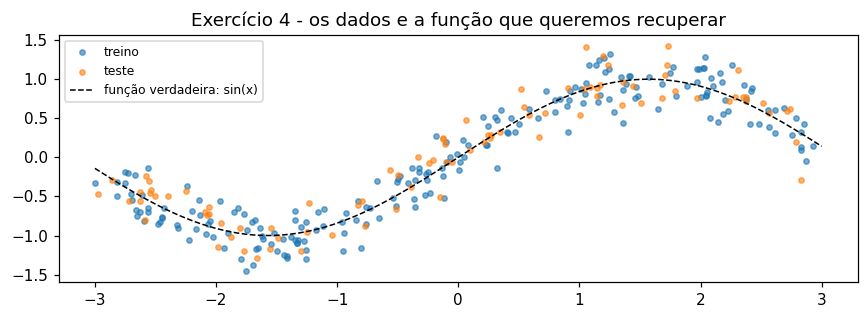

In [66]:
# ============================ COLETA DE DADOS - EXERCÍCIO 4 ============================
# Fonte: gerador sintético com função conhecida (offline).
rng_ex4 = np.random.RandomState(3)

X_ex4 = rng_ex4.uniform(-3, 3, 300).reshape(-1, 1)            # 300 valores de x entre -3 e 3
ruido = rng_ex4.normal(0, 0.2, 300)                           # ruído gaussiano
y_ex4 = np.sin(X_ex4).ravel() + ruido                         # a função VERDADEIRA é o seno

# O passo que muda tudo neste exercício: separar treino e teste.
X_tr4, X_te4, y_tr4, y_te4 = train_test_split(X_ex4, y_ex4, test_size=0.3, random_state=3)

print("treino:", X_tr4.shape, "| teste:", X_te4.shape)  # 70% para ajustar, 30% para avaliar

plt.figure(figsize=(8, 3))                    # cria a figura
plt.scatter(X_tr4, y_tr4, s=12, alpha=0.6, label="treino")    # pontos usados para ajustar
plt.scatter(X_te4, y_te4, s=12, alpha=0.6, label="teste")     # pontos reservados para avaliar
grade_ex4 = np.linspace(-3, 3, 300).reshape(-1, 1)            # grade para desenhar a curva teórica
plt.plot(grade_ex4, np.sin(grade_ex4), "k--", lw=1, label="função verdadeira: sin(x)")  # "k--" = linha preta tracejada
plt.legend(fontsize=8)                        # mostra a legenda
plt.title("Exercício 4 - os dados e a função que queremos recuperar")  # título do gráfico
plt.tight_layout()                            # ajusta os espaçamentos para nada se sobrepor
plt.show()                                    # desenha a figura aqui no notebook

# A PARTIR DAQUI É COM VOCÊ: passos 2 a 5 do enunciado.

---
## Exercício 5 — Escrevendo (e otimizando) o transformador `LogSeguro`

**Objetivo:** construir um transformador customizado de verdade — que **aprende**
algo no `fit` e cujo hiperparâmetro pode ser otimizado por `GridSearchCV`.

### O problema

Aplicar `log1p` em toda coluna é burrice: colunas já simétricas só perdem
interpretabilidade, e colunas com valores negativos geram `NaN`. Queremos um
transformador que decida, **coluna a coluna e apenas com os dados de treino**,
onde o log vale a pena.

### Passo 1 — Colete os dados

A célula de coleta monta um DataFrame com 4 colunas de assimetrias bem diferentes:

| Coluna | Distribuição | Assimetria esperada |
|---|---|---|
| `renda` | log-normal | alta e positiva |
| `idade` | normal | ~ 0 |
| `visitas` | exponencial | alta e positiva |
| `nota` | uniforme | ~ 0 |

Calcule `scipy.stats.skew` em cada coluna **antes** de começar e anote os valores:
são eles que seu transformador vai usar para decidir.

### Passo 2 — Implemente a classe

```python
class LogSeguro(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=1.0):
        self.threshold = threshold          # só guarda o parâmetro, sem validar

    def fit(self, X, y=None):
        # 1. converta X para array (np.asarray) e guarde n_features_in_
        # 2. calcule a assimetria de cada coluna com scipy.stats.skew
        # 3. guarde em self.colunas_log_ um vetor booleano:
        #    True onde skew > self.threshold  E  o mínimo da coluna é >= 0
        #    (a segunda condição evita log de número negativo)
        return self

    def transform(self, X):
        # 1. check_is_fitted(self)
        # 2. copie X (não altere o original!)
        # 3. aplique np.log1p SÓ nas colunas marcadas em self.colunas_log_
        return X_out
```

### Passo 3 — Teste o contrato do scikit-learn

Seu transformador precisa passar nestes três testes:

```python
LogSeguro().fit(X_tr).transform(X_te)                  # 1. fit/transform separados
LogSeguro(threshold=0.5).get_params()                  # 2. get_params funciona
make_pipeline(LogSeguro(), StandardScaler()).fit(X_tr) # 3. encaixa em Pipeline
```

Bônus: `from sklearn.utils.estimator_checks import check_estimator; check_estimator(LogSeguro())`
roda a bateria oficial de testes do sklearn. Não se assuste se falhar de primeira —
leia a mensagem e corrija.

### Passo 4 — Otimize o `threshold`

Crie um alvo de regressão (a célula de coleta já fornece um) e otimize:

```python
pipe = Pipeline([("log", LogSeguro()), ("sc", StandardScaler()), ("reg", Ridge())])
grade = {"log__threshold": [0.0, 0.5, 1.0, 2.0, 10.0]}   # 10.0 = praticamente desliga o log
busca = GridSearchCV(pipe, grade, cv=5, scoring="r2").fit(X_tr, y_tr)
print(busca.best_params_, busca.best_score_)
```

Note a sintaxe `nome_do_passo__nome_do_parametro` — dois underscores.

### Passo 5 — Interprete

1. Qual `threshold` venceu? Quais colunas ele acabou transformando?
   (`busca.best_estimator_.named_steps["log"].colunas_log_`)
2. O que acontece com `threshold=10.0`? Por que esse valor serve de **controle**
   do experimento?

### O que entregar

O código da classe, a saída do `GridSearchCV` e a lista de colunas efetivamente
transformadas pelo melhor modelo.

In [67]:
# ============================ COLETA DE DADOS - EXERCÍCIO 5 ============================
# Fonte: gerador sintético com assimetrias controladas (offline).
from scipy import stats                                # stats.skew mede a assimetria
from sklearn.linear_model import Ridge                 # regressão linear com regularização L2
from sklearn.model_selection import GridSearchCV       # busca em grade de hiperparâmetros

rng_ex5 = np.random.RandomState(21)           # semente própria deste exercício
n_ex5 = 600                                   # 600 clientes fictícios

df_ex5 = pd.DataFrame({                       # cada chave do dicionário vira uma coluna
    "renda":   rng_ex5.lognormal(8.0, 0.9, n_ex5),     # cauda longa à direita
    "idade":   rng_ex5.normal(40, 12, n_ex5),          # simétrica
    "visitas": rng_ex5.exponential(3, n_ex5),          # muito assimétrica
    "nota":    rng_ex5.uniform(0, 10, n_ex5),          # simétrica, sem cauda
})

# Alvo de regressão construído a partir do LOG da renda: por isso o log ajuda tanto aqui.
y_ex5 = (0.8 * np.log1p(df_ex5["renda"])
         + 0.03 * df_ex5["idade"]
         - 0.2 * np.log1p(df_ex5["visitas"])
         + rng_ex5.normal(0, 0.4, n_ex5)).values

X_tr5, X_te5, y_tr5, y_te5 = train_test_split(df_ex5, y_ex5, test_size=0.25, random_state=21)  # 75% treino / 25% teste

# A assimetria de cada coluna - é esta a informação que o LogSeguro vai aprender no fit.
print("assimetria (skew) de cada coluna, no TREINO:")
print(X_tr5.apply(stats.skew).round(2))                # .apply roda a função em cada coluna
print("\nmínimo de cada coluna (o log exige valores >= 0):")  # rótulo da saída
print(X_tr5.min().round(2))                   # aqui são todas positivas, mas seu código deve checar

# A PARTIR DAQUI É COM VOCÊ: implemente a classe LogSeguro e siga os passos 3 a 5.

assimetria (skew) de cada coluna, no TREINO:
renda      3.73
idade     -0.05
visitas    2.11
nota       0.01
dtype: float64

mínimo de cada coluna (o log exige valores >= 0):
renda      153.50
idade        5.99
visitas      0.01
nota         0.01
dtype: float64


---
## Exercício 6 — Pipeline completo em dados reais e sujos (Titanic)

**Objetivo:** o exercício-síntese. Dados reais, com NaN, texto livre, categóricas e
numéricas na mesma tabela — e um `GridSearchCV` otimizando **as decisões de
pré-processamento** junto com o modelo.

### Passo 1 — Colete os dados

Três caminhos, em ordem de preferência (a célula de coleta tenta os três):

1. **OpenML** (recomendado, dados crus):
   ```python
   from sklearn.datasets import fetch_openml
   titanic = fetch_openml("titanic", version=1, as_frame=True)
   df = titanic.frame
   ```
   Baixa 1.309 passageiros na primeira execução e guarda em cache
   (`~/scikit_learn_data`). Sempre fixe a `version` para o resultado ser reproduzível.

2. **seaborn** (891 linhas, versão mais conhecida):
   ```python
   import seaborn as sns
   df = sns.load_dataset("titanic")
   ```

3. **CSV local do repositório**, sem internet:
   ```python
   df = pd.read_csv(Path("..") / "AULA1" / "titanic_tratado.csv")
   ```
   Atenção: esse arquivo **já está pré-processado** (as categóricas foram
   codificadas). Serve de plano B, mas tira boa parte da graça do exercício.

### Passo 2 — Conheça os dados antes de modelar

Responda, com código:

1. `df.shape`, `df.dtypes` — quantas colunas numéricas e quantas de texto?
2. `df.isna().sum().sort_values(ascending=False)` — quais colunas têm NaN e quantos?
3. `df["survived"].value_counts(normalize=True)` — o dataset é balanceado?
4. Para cada coluna de texto, `df[col].nunique()` — quais são categóricas de baixa
   cardinalidade e quais são praticamente identificadores?

### Passo 3 — Decida o destino de cada coluna

Monte uma tabela de decisão antes de escrever o `ColumnTransformer`:

| Coluna | Tipo | Decisão | Motivo |
|---|---|---|---|
| `pclass` | ordinal (1ª, 2ª, 3ª classe) | ? | tem ordem natural |
| `sex` | binária | ? | |
| `age` | numérica com ~20% de NaN | ? | |
| `fare` | numérica assimétrica | ? | |
| `sibsp`, `parch` | contagens | ? | |
| `embarked` | nominal com poucos NaN | ? | |
| `cabin` | texto, >70% NaN | ? | |
| `name`, `ticket`, `boat`, `body`, `home.dest` | identificadores / vazamento | ? | |

> **Cuidado com o vazamento:** em algumas versões do Titanic existem as colunas
> `boat` (bote salva-vidas) e `body` (número do corpo recuperado). Elas **revelam o
> alvo**. Se o seu modelo chegar a 100% de acurácia, foi isso que aconteceu.

### Passo 4 — Construa o pipeline

```python
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer()), ("sc", StandardScaler())]), colunas_num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OneHotEncoder(handle_unknown="ignore"))]), colunas_cat),
])
modelo = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
```

### Passo 5 — Otimize pré-processamento E modelo juntos

Esta é a parte que dá nome ao exercício: o `GridSearchCV` pode buscar dentro das
etapas do pipeline usando `__`.

```python
grade = {
    "pre__num__imp__strategy": ["mean", "median"],
    "pre__cat__enc__min_frequency": [None, 0.02],
    "clf__C": [0.1, 1.0, 10.0],
}
busca = GridSearchCV(modelo, grade, cv=5, scoring="roc_auc", n_jobs=-1)
busca.fit(X_tr, y_tr)
```

### Passo 6 — Engenharia de features (opcional, mas é onde se ganha)

Crie com `FunctionTransformer` ou com uma classe própria:

- `tamanho_familia = sibsp + parch + 1`;
- `sozinho = (tamanho_familia == 1)`;
- **título** extraído do nome (`Mr`, `Mrs`, `Miss`, `Master`, ...) — use
  `df["name"].str.extract(r",\s*([^\.]+)\.")` e agrupe os títulos raros;
- `tem_cabine = cabin.notna()` — a *ausência* do dado é informativa aqui.

Meça o AUC antes e depois dessas features.

### O que entregar

1. A tabela de decisão do Passo 3, preenchida;
2. `busca.best_params_` e o AUC no conjunto de teste (que você só pode tocar no fim);
3. As 10 features mais importantes do melhor modelo
   (`busca.best_estimator_.named_steps["clf"].coef_` cruzado com
   `get_feature_names_out()`);
4. Uma conclusão de 5 linhas: qual decisão de pré-processamento fez mais diferença?

In [68]:
# ============================ COLETA DE DADOS - EXERCÍCIO 6 ============================
# Fonte: dados reais. Tentamos três caminhos, do melhor para o plano B.
from pathlib import Path

df_ex6 = None                                          # vai receber o DataFrame que der certo
origem = None                                          # e guardamos de onde ele veio

# --- Caminho 1: OpenML (dados crus, 1309 passageiros) ---------------------------------
try:
    titanic_ex6 = fetch_openml("titanic", version=1, as_frame=True)  # baixa na 1ª vez; depois vem do cache em disco
    df_ex6 = titanic_ex6.frame.copy()                  # .frame já traz features e alvo juntos
    df_ex6["survived"] = df_ex6["survived"].astype(int)   # vem como category: convertemos para 0/1
    origem = "OpenML (fetch_openml)"          # registra qual caminho funcionou
except Exception as erro:                     # sem rede? tentamos a próxima fonte
    print("OpenML indisponível:", type(erro).__name__)  # informa o motivo, sem parar o notebook

# --- Caminho 2: seaborn (891 passageiros) ---------------------------------------------
if df_ex6 is None:
    try:                                      # se a fonte falhar, seguimos sem quebrar a célula
        import seaborn as sns                 # o seaborn também traz datasets clássicos
        df_ex6 = sns.load_dataset("titanic")  # versão com 891 linhas
        origem = "seaborn"                    # registra qual caminho funcionou
    except Exception as erro:                 # sem rede? tentamos a próxima fonte
        print("seaborn indisponível:", type(erro).__name__)  # idem: informa e segue

# --- Caminho 3: CSV local do repositório (offline, porém já pré-processado) ------------
if df_ex6 is None:
    caminho = Path("..") / "AULA1" / "titanic_tratado.csv"  # sobe um nível e entra na pasta AULA1
    if caminho.exists():                      # só tenta ler se o arquivo realmente existir
        df_ex6 = pd.read_csv(caminho)         # plano B: dados já pré-processados
        origem = f"CSV local ({caminho})"     # registra qual caminho funcionou

print("origem dos dados:", origem)            # sempre saiba de onde veio o seu dado
print("shape:", df_ex6.shape)                 # 1309 linhas x 14 colunas na versão do OpenML
print("\ntipos de dados:")                    # rótulo da saída
print(df_ex6.dtypes.value_counts())                    # quantas colunas de cada tipo

print("\nvalores faltantes por coluna (só as que têm):")  # rótulo da saída
faltantes = df_ex6.isna().sum()                        # conta NaN por coluna
print(faltantes[faltantes > 0].sort_values(ascending=False))  # filtra só as colunas com NaN e ordena pela quantidade

print("\ndistribuição do alvo:")              # rótulo da saída
print(df_ex6["survived"].value_counts(normalize=True).round(3))  # normalize=True devolve proporções em vez de contagens

print("\ncardinalidade das colunas de texto:")  # rótulo da saída
# select_dtypes filtra colunas por tipo; object/category = texto.
for col in df_ex6.select_dtypes(include=["object", "category"]).columns:
    print(f"  {col:12s} {df_ex6[col].nunique():5d} valores distintos")  # name tem ~1300: é identificador, não categoria

df_ex6.head()                                 # as 5 primeiras linhas, exibidas pelo Jupyter

# A PARTIR DAQUI É COM VOCÊ: passos 2 a 6 do enunciado.
# LEMBRE-SE: remova as colunas que vazam o alvo (boat, body) antes de modelar.

origem dos dados: OpenML (fetch_openml)
shape: (1309, 14)

tipos de dados:
object      5
int64       4
float64     3
category    1
category    1
Name: count, dtype: int64

valores faltantes por coluna (só as que têm):
body         1188
cabin        1014
boat          823
home.dest     564
age           263
embarked        2
fare            1
dtype: int64

distribuição do alvo:
survived
0    0.618
1    0.382
Name: proportion, dtype: float64

cardinalidade das colunas de texto:


  name          1307 valores distintos
  sex              2 valores distintos
  ticket         929 valores distintos
  cabin          186 valores distintos
  embarked         3 valores distintos
  boat            27 valores distintos
  home.dest      369 valores distintos


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.000,0,0,24160,211.338,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.917,1,2,113781,151.550,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.000,1,2,113781,151.550,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.000,1,2,113781,151.550,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.000,1,2,113781,151.550,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


---
## Desafio final — Traga o seu próprio dataset

Os exercícios acima usam dados que alguém já arrumou para você. No trabalho, o dado
chega bruto. Feche o notebook com um dataset **escolhido por você**:

### Como encontrar um dataset

1. **OpenML** — catálogo com milhares de datasets, acessível por código:
   ```python
   from sklearn.datasets import fetch_openml
   dados = fetch_openml(data_id=42165, as_frame=True)   # Ames Housing (regressão)
   ```
   Procure por tema em <https://www.openml.org/search?type=data> e use o `data_id`
   que aparece na URL.

2. **UCI Machine Learning Repository** — o clássico, com o pacote `ucimlrepo`
   (o mesmo usado na AULA 2):
   ```python
   from ucimlrepo import fetch_ucirepo
   adult = fetch_ucirepo(id=2)          # Census Income: ótimo para categóricas
   X, y = adult.data.features, adult.data.targets
   ```
   Sugestões com muitas categóricas: `id=2` (Adult), `id=222` (Bank Marketing),
   `id=45` (Heart Disease), `id=350` (Default of Credit Card Clients).

3. **dados.gov.br / Portal da Transparência / IBGE** — dados públicos brasileiros
   em CSV. Baixe o arquivo e carregue com
   `pd.read_csv(caminho, sep=";", decimal=",", encoding="latin-1")` — o encoding
   `latin-1` resolve a maioria dos acentos quebrados em arquivos públicos.

4. **Kaggle** — `kaggle datasets download -d <usuario>/<dataset>` (requer conta e
   token de API).

### O roteiro mínimo de entrega

1. Descreva a origem do dado, o número de linhas/colunas e o que é o alvo;
2. Faça o diagnóstico: tipos, NaN, cardinalidade, escala, assimetria, outliers;
3. Justifique **cada** escolha de pré-processamento com uma evidência do diagnóstico;
4. Monte um `ColumnTransformer` + `Pipeline` e avalie com validação cruzada;
5. Compare com uma linha de base ingênua (`DummyClassifier` ou `DummyRegressor`) —
   se o seu pipeline não vence o Dummy, o problema não é o modelo, é o dado;
6. Salve o pipeline treinado com `joblib.dump(modelo, "modelo.pkl")` e mostre que
   ele volta a funcionar com `joblib.load`.

---

## Para ir além

- [Preprocessing data](https://scikit-learn.org/stable/modules/preprocessing.html) — a página original
- [Compare the effect of different scalers on data with outliers](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html)
- [Column Transformer with Mixed Types](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html)
- [Time-related feature engineering](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html)
- [Dataset loading utilities](https://scikit-learn.org/stable/datasets.html) — o guia completo de como o sklearn carrega dados